# Expérience 6 — ultra-haute fidélité sur CAMUS (RTX 4060 Ti)

Ce notebook reconstruit des coupes d'échocardiographie 2D (jeu CAMUS, images `camus_64`) avec un `AutoencoderKL` de MONAI. Il reprend la graine, le découpage par patient et la normalisation des expériences 1 à 5. L'expérience 5 a atteint MSE test 0,00268, MSE cœur 0,00446, SSIM 0,808, PSNR 26,04 dB, PSNR cœur 23,73 dB, Spearman(z0, aire du VG) 0,933 (`artifacts/results_exp5.json`). Ici la durée n'est plus une contrainte : la reconstruction doit se rapprocher de l'image d'origine, et trois axes latents portent les trois attributs cardiaques.

Cinq leviers :

1. **Capacité.** Canaux `(64, 128, 256, 512)`, trois blocs résiduels par échelle, attention aux grilles 16×16 et 8×8. Le code latent passe à 16×8×8, soit 1024 coefficients. Treize canaux restent libres pour le grain échographique.
2. **Perte multi-échelle.** MSE pondérée, L1 pondérée, SSIM à 64×64 et à 32×32, L1 des gradients et L1 des amplitudes FFT. Le cœur pèse `W = 1 + 4 · 1(label > 0)`.
3. **Trois axes AR-VAE.** β monte jusqu'à `10⁻⁵` en 20 époques. γ = 0,025 est partagé entre l'aire de la cavité (`z0`), le myocarde (`z1`, `label == 2`) et l'oreillette gauche (`z2`).
4. **Cent cinquante époques et EMA.** AdamW à `8×10⁻⁴`, cosinus jusqu'à `5×10⁻⁶`, lot de 32. À l'entraînement le décodeur voit `z = μ + εσ`. En validation et au test il voit `μ`. À partir de l'époque 20, le checkpoint est la plus faible reconstruction de validation des poids lissés (`ema_decay = 0,995`).
5. **FP32, sans synchronisation par lot.** Pas de précision mixte ni de TF32. Les images d'entraînement et de validation sont préchargées en VRAM. Les moyennes d'époque ne reviennent sur le CPU qu'une fois par époque, et le fichier `.pth` n'est écrit qu'à la fin.

La barre de cette expérience est de dépasser l'expérience 5 sur la MSE globale, la MSE cœur, le SSIM et le PSNR, avec Spearman(z0, aire du VG) > 0,85. Les cibles visées sont MSE test < 0,0018, MSE cœur < 0,0030, SSIM > 0,85 et PSNR > 27,5 dB.


In [1]:
%matplotlib inline

import json
import os
import random
import time
import zipfile
from collections import Counter
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import monai
import nibabel as nib
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from monai.data import DataLoader
from monai.losses import SSIMLoss
from monai.metrics import PSNRMetric, SSIMMetric
from monai.networks.nets import AutoencoderKL
from monai.utils import set_determinism
from scipy.stats import pearsonr, spearmanr
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset as TorchDataset
from torchinfo import summary

print(f"PyTorch {torch.__version__}  |  MONAI {monai.__version__}  |  NumPy {np.__version__}")


PyTorch 2.7.0+cu128  |  MONAI 1.5.2  |  NumPy 2.5.3


In [2]:
SEED = 12345


def enable_fast_cuda():
    # FP32 pur : TF32 réduit la mantisse des convolutions et des produits matriciels.
    # set_determinism force benchmark=False. On le rétablit ensuite, la taille 64×64 est fixe.
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.set_float32_matmul_precision("highest")
    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    set_determinism(seed=seed)
    enable_fast_cuda()


set_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA est indisponible dans cet interpréteur "
        f"(PyTorch {torch.__version__}). Relancer le notebook avec le Python "
        "qui fournit un wheel +cu128 ou +cu124."
    )

device = torch.device("cuda")
gpu_name = torch.cuda.get_device_name(0)
gpu_props = torch.cuda.get_device_properties(0)
vram_total = gpu_props.total_memory
vram_allocated = torch.cuda.memory_allocated(0)
print(f"Périphérique : {device}")
print(f"GPU : {gpu_name}")
print(f"VRAM totale : {vram_total / 1024 ** 3:.2f} Go")
print(f"VRAM allouée : {vram_allocated / 1024 ** 2:.1f} Mo")
print(f"PyTorch CUDA : {torch.version.cuda}")

CHECKPOINT_DIR = Path("checkpoints")
ARTIFACT_DIR = Path("artifacts")
CHECKPOINT_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "exp6_vae_best.pth"


Périphérique : cuda
GPU : NVIDIA GeForce RTX 4060 Ti
VRAM totale : 8.00 Go
VRAM allouée : 0.0 Mo
PyTorch CUDA : 12.8


## 1. Audit et préparation des données

Les images restent hors du dépôt. Le dossier est `CAMUS_DATA_ROOT` s'il est défini, sinon `../camus_64`, sinon `data/camus_64`. Si aucun des trois n'existe, l'archive du cours est téléchargée.


In [3]:
if os.environ.get("CAMUS_DATA_ROOT"):
    root = Path(os.environ["CAMUS_DATA_ROOT"]).expanduser().resolve()
    data_dir = root if root.name.startswith("camus_") else root / "camus_64"
elif (Path("..") / "camus_64").resolve().is_dir():
    data_dir = (Path("..") / "camus_64").resolve()
elif (Path("data") / "camus_64").resolve().is_dir():
    data_dir = (Path("data") / "camus_64").resolve()
else:
    data_dir = (Path("data") / "camus_64").resolve()

if not data_dir.is_dir():
    zip_url = "https://www.creatis.insa-lyon.fr/~bernard/camus/camus_64.zip"
    print(f"{data_dir} est absent. Téléchargement de {zip_url}")
    data_dir.parent.mkdir(parents=True, exist_ok=True)
    with urlopen(zip_url, timeout=180) as response:
        payload = response.read()
    with zipfile.ZipFile(BytesIO(payload)) as archive:
        archive.extractall(data_dir.parent)
    print(f"Archive extraite dans {data_dir}")
else:
    print(f"Données locales : {data_dir}")

assert data_dir.is_dir(), f"Dossier CAMUS introuvable : {data_dir}"


Données locales : C:\Users\trans\OneDrive\Documents\INSA Lyon\5TCA\IAV\camus_64


### Découpage par patient

Même graine et même appel à `train_test_split` que les expériences 2 et 3 : 400 patients d'entraînement, 50 de validation, 50 de test. Un patient n'apparaît que dans un seul sous-ensemble. `patient0010` sert plus loin à l'interpolation ED vers ES.


In [4]:
def subdirs(folder, join=True, prefix=None, suffix=None, sort=True):
    joiner = os.path.join if join else (lambda root, name: name)
    names = [
        joiner(folder, name)
        for name in os.listdir(folder)
        if os.path.isdir(os.path.join(folder, name))
        and (prefix is None or name.startswith(prefix))
        and (suffix is None or name.endswith(suffix))
    ]
    if sort:
        names.sort()
    return names


data_dir = data_dir.resolve()
keys = subdirs(data_dir, prefix="patient", join=False)
train_keys, val_and_test_keys = train_test_split(keys, train_size=0.8, random_state=SEED)
val_keys, test_keys = train_test_split(val_and_test_keys, test_size=0.5, random_state=SEED)
train_keys, val_keys, test_keys = sorted(train_keys), sorted(val_keys), sorted(test_keys)

assert set(train_keys).isdisjoint(val_keys)
assert set(train_keys).isdisjoint(test_keys)
assert set(val_keys).isdisjoint(test_keys)
assert (len(train_keys), len(val_keys), len(test_keys)) == (400, 50, 50)

example_image = data_dir / keys[0] / f"{keys[0]}_2CH_ED.nii.gz"
assert example_image.is_file(), f"Image introuvable : {example_image}"
print(f"Patients : entraînement {len(train_keys)}, validation {len(val_keys)}, test {len(test_keys)}")
print(f"Exemple lu : {example_image.name}")
print(f"patient0010 est dans le test : {'patient0010' in test_keys}")
assert "patient0010" in test_keys


Patients : entraînement 400, validation 50, test 50
Exemple lu : patient0001_2CH_ED.nii.gz
patient0010 est dans le test : True


### Jeu de données

Chaque cadre est lu une fois et gardé en mémoire. Les intensités supérieures à 1 sont divisées par 255, ce qui ramène les images 8 bits dans [0, 1]. `lv_area` est la proportion de pixels dont le masque vaut 1, la cavité ventriculaire gauche. `epi_area` est le myocarde seul (`label == 2`), et non plus la réunion de la cavité et du myocarde utilisée dans l'expérience 5. `la_area` est l'oreillette (`label == 3`). Ces trois aires supervisent `μ[:, 0]`, `μ[:, 1]` et `μ[:, 2]`. Elles ne rentrent pas dans l'encodeur.


In [5]:
IMAGE_SIZE = 64
IN_CHANNELS = 1
VIEWS = ("2CH_ED", "2CH_ES", "4CH_ED", "4CH_ES")
LABEL_NAMES = {0: "fond", 1: "cavité VG", 2: "myocarde", 3: "oreillette gauche"}
HEART_CMAP = ListedColormap(["#202020", "#d62728", "#2ca02c", "#1f77b4"])


def load_nifti(path):
    array = np.squeeze(nib.load(str(path)).get_fdata())
    if array.ndim != 2:
        raise ValueError(f"Image 2D attendue dans {path}, forme {array.shape}")
    return np.ascontiguousarray(array.T)


def read_info(path):
    info = {}
    if not path.exists():
        return info
    for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
        if ":" not in line:
            continue
        key, value = line.split(":", 1)
        info[key.strip()] = value.strip()
    return info


def build_records(patient_keys):
    records = []
    for patient in patient_keys:
        folder = data_dir / patient
        for view_instant in VIEWS:
            view, instant = view_instant.split("_")
            info = read_info(folder / f"Info_{view}.cfg")
            image = load_nifti(folder / f"{patient}_{view_instant}.nii.gz").astype(np.float32)
            if image.max() > 1:
                image = image / 255.0
            label = load_nifti(folder / f"{patient}_{view_instant}_gt.nii.gz").astype(np.int64)
            try:
                ef = float(info.get("EF", "nan"))
            except ValueError:
                ef = float("nan")
            records.append({
                "image": torch.from_numpy(image[None]),
                "label": torch.from_numpy(label),
                "lv_area": float((label == 1).mean()),
                "epi_area": float((label == 2).mean()),
                "la_area": float((label == 3).mean()),
                "patient": patient,
                "view": view,
                "instant": instant,
                "view_instant": view_instant,
                "ef": ef,
                "quality": info.get("ImageQuality", "NA"),
            })
    return records


class CamusDataset(TorchDataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        return self.records[index]


print("Chargement des cadres NIfTI en mémoire...")
t0 = time.perf_counter()
train_dataset = CamusDataset(build_records(train_keys))
valid_dataset = CamusDataset(build_records(val_keys))
test_dataset = CamusDataset(build_records(test_keys))
print(
    f"{len(train_dataset) + len(valid_dataset) + len(test_dataset)} cadres "
    f"en cache en {time.perf_counter() - t0:.1f} s"
)

sample = train_dataset[0]
print(
    f"Image : {tuple(sample['image'].shape)}  "
    f"[{float(sample['image'].min()):.3f}, {float(sample['image'].max()):.3f}]"
)
print(f"Masque : {tuple(sample['label'].shape)}  classes {torch.unique(sample['label']).tolist()}")
print(
    f"lv_area {sample['lv_area']:.4f}  "
    f"epi_area {sample['epi_area']:.4f}  "
    f"la_area {sample['la_area']:.4f}"
)
print("Convention des masques :", LABEL_NAMES)


Chargement des cadres NIfTI en mémoire...


2000 cadres en cache en 2.7 s
Image : (1, 64, 64)  [0.000, 1.000]
Masque : (64, 64)  classes [0, 1, 2, 3]
lv_area 0.1348  epi_area 0.1057  la_area 0.0488
Convention des masques : {0: 'fond', 1: 'cavité VG', 2: 'myocarde', 3: 'oreillette gauche'}


### Chargeurs

Les tenseurs sont d'abord en RAM pour l'audit et pour le jeu de test, qui a besoin des métadonnées patient et vue. `num_workers` reste à 0 : sous Windows, un processus de chargement supplémentaire n'apporte rien. Avant la boucle d'entraînement, les images et les masques d'entraînement et de validation sont empilés une fois en VRAM. Le test reste sur le chargeur CPU : il n'est lu qu'une fois, après le checkpoint.

In [6]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True,
)
valid_loader = DataLoader(
    valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True,
)

print(f"Images d'entraînement : {len(train_loader.dataset)}")
print(f"Images de validation :  {len(valid_loader.dataset)}")
print(f"Images de test :        {len(test_loader.dataset)}")

assert test_loader.dataset is test_dataset
assert test_loader.dataset is not valid_dataset
assert len(test_loader.dataset) == len(test_dataset) == 200
assert len(train_loader.dataset) == 1600
assert set(test_keys).isdisjoint(val_keys)
assert set(test_keys).isdisjoint(train_keys)
print("Le chargeur de test lit les patients tenus à l'écart. Effectif égal à la validation, patients différents.")


Images d'entraînement : 1600
Images de validation :  200
Images de test :        200
Le chargeur de test lit les patients tenus à l'écart. Effectif égal à la validation, patients différents.


### Contrôle des intensités, des vues et de l'aire du VG

`lv_area` doit coïncider avec la fraction de pixels de cavité, et la télédiastole doit occuper plus de pixels que la télésystole sur l'entraînement.


Forme unique : (1, 64, 64)   canal d'entrée in_channels=1
Intensités sur les trois sous-ensembles : [0.000, 1.000]
Collation de lv_area : tenseur (32,), aligné sur le masque.
entraînement   {'2CH_ED': 400, '2CH_ES': 400, '4CH_ED': 400, '4CH_ES': 400}  lv_area ED 0.1129  ES 0.0717
validation     {'2CH_ED': 50, '2CH_ES': 50, '4CH_ED': 50, '4CH_ES': 50}  lv_area ED 0.1050  ES 0.0658
test           {'2CH_ED': 50, '2CH_ES': 50, '4CH_ED': 50, '4CH_ES': 50}  lv_area ED 0.1212  ES 0.0783
Fraction moyenne de pixels cœur (label > 0) sur l'entraînement : 0.245
Aire moyenne de la cavité VG sur l'entraînement : 0.092


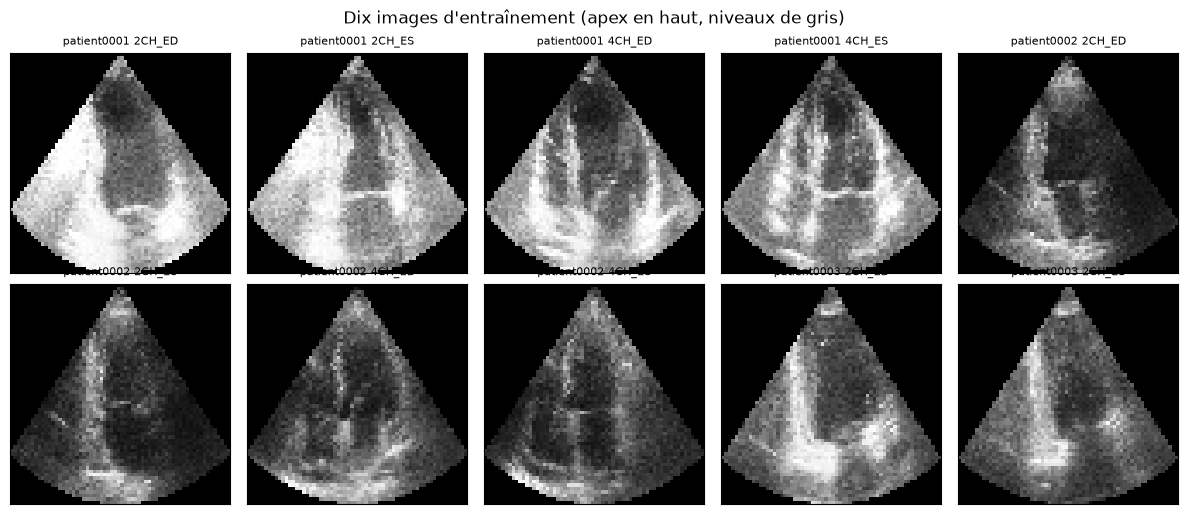

In [7]:
shapes = set()
mins, maxs = [], []
for subset in (train_dataset, valid_dataset, test_dataset):
    for record in subset.records:
        image = record["image"]
        shapes.add(tuple(image.shape))
        mins.append(float(image.min()))
        maxs.append(float(image.max()))
        stored = record["lv_area"]
        computed = float((record["label"].numpy() == 1).mean())
        assert abs(stored - computed) < 1e-6
        label_np = record["label"].numpy()
        assert abs(record["epi_area"] - float((label_np == 2).mean())) < 1e-6
        assert abs(record["la_area"] - float((label_np == 3).mean())) < 1e-6

assert shapes == {(IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE)}, shapes
assert min(mins) >= 0.0 and max(maxs) <= 1.0
print(f"Forme unique : {shapes.pop()}   canal d'entrée in_channels={IN_CHANNELS}")
print(f"Intensités sur les trois sous-ensembles : [{min(mins):.3f}, {max(maxs):.3f}]")

probe_batch = next(iter(train_loader))
area_batch = torch.as_tensor(probe_batch["lv_area"], dtype=torch.float32)
area_from_label = (probe_batch["label"] == 1).float().mean(dim=(1, 2))
assert torch.allclose(area_batch, area_from_label, atol=1e-5)
print(f"Collation de lv_area : tenseur {tuple(area_batch.shape)}, aligné sur le masque.")


def mean_lv_area(records, instant=None, view=None):
    values = [
        record["lv_area"]
        for record in records
        if (instant is None or record["instant"] == instant)
        and (view is None or record["view"] == view)
    ]
    return float(np.mean(values))


for name, subset in (
    ("entraînement", train_dataset),
    ("validation", valid_dataset),
    ("test", test_dataset),
):
    counts = Counter(record["view_instant"] for record in subset.records)
    print(
        f"{name:14s} {dict(sorted(counts.items()))}  "
        f"lv_area ED {mean_lv_area(subset.records, 'ED'):.4f}  "
        f"ES {mean_lv_area(subset.records, 'ES'):.4f}"
    )

assert mean_lv_area(train_dataset.records, "ED") > mean_lv_area(train_dataset.records, "ES")
heart_fraction = float(np.mean([
    (record["label"] > 0).float().mean().item()
    for record in train_dataset.records
]))
print(f"Fraction moyenne de pixels cœur (label > 0) sur l'entraînement : {heart_fraction:.3f}")
print(f"Aire moyenne de la cavité VG sur l'entraînement : {mean_lv_area(train_dataset.records):.3f}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for ax, index in zip(axes.ravel(), range(10)):
    record = train_dataset[index]
    ax.imshow(record["image"][0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{record['patient']} {record['view_instant']}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Dix images d'entraînement (apex en haut, niveaux de gris)")
fig.tight_layout()
plt.show()


## 2. Architecture (`AutoencoderKL`)

L'encodeur produit les paramètres d'une gaussienne diagonale. Trois sous-échantillonnages mènent de 64×64 à 8×8. Seize canaux latents donnent un code 16×8×8, soit 1024 coefficients. Les largeurs `(64, 128, 256, 512)` sont toutes divisibles par 32, donc la GroupNorm reste en place. Trois blocs résiduels à chaque échelle donnent de la profondeur pour les parois fines et le speckle. L'attention est active aux deux dernières échelles, 16×16 et 8×8 : la première relie les quatre cavités, la seconde détaille valves et parois.

À l'entraînement, le décodeur reçoit z = μ + ε σ. À l'évaluation, il reçoit μ. `forward` rééchantillonne même en mode `eval`, donc l'entraînement et la validation appellent `encode`, `sampling` et `decode` explicitement. `decode_image` borne la sortie à [0, 1] avant la perte et avant les métriques. Le gradient traverse ce bornage : au démarrage le décodeur sort largement de [0, 1], et un clamp dur annule alors l'apprentissage.

Le calcul reste en FP32. TF32 est désactivé dans la cellule de réglage CUDA : les convolutions et les produits matriciels gardent la mantisse 23 bits.


In [8]:
CHANNELS = (64, 128, 256, 512)
LATENT_CHANNELS = 16
ATTENTION_LEVELS = (False, False, True, True)
NORM_GROUPS = 32
NUM_RES_BLOCKS = 3

assert all(channel % NORM_GROUPS == 0 for channel in CHANNELS)
assert len(ATTENTION_LEVELS) == len(CHANNELS)


def build_vae(seed=SEED):
    set_seed(seed)
    model = AutoencoderKL(
        spatial_dims=2,
        in_channels=IN_CHANNELS,
        out_channels=1,
        num_res_blocks=NUM_RES_BLOCKS,
        channels=CHANNELS,
        attention_levels=ATTENTION_LEVELS,
        latent_channels=LATENT_CHANNELS,
        norm_num_groups=NORM_GROUPS,
        with_encoder_nonlocal_attn=False,
        with_decoder_nonlocal_attn=False,
    )
    return model.to(device)


def decode_image(net, latent):
    raw = net.decode(latent)
    clamped = torch.clamp(raw, 0.0, 1.0)
    # Le forward reste dans [0, 1]. Le gradient traverse les pixels saturés :
    # avec ce décodeur le signal démarre hors de [0, 1], et un clamp dur fige l'apprentissage.
    return raw + (clamped - raw).detach()


model = build_vae(SEED)
print(summary(
    model.cpu(),
    input_size=(BATCH_SIZE, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE),
    depth=2,
    col_names=["input_size", "output_size", "num_params"],
    verbose=0,
    device="cpu",
))
model.to(device)

with torch.no_grad():
    probe, mu, sigma = model(torch.zeros(1, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE, device=device))

LATENT_SHAPE = tuple(mu.shape[1:])
downsamples = len(CHANNELS) - 1
expected_latent = (
    LATENT_CHANNELS,
    IMAGE_SIZE // 2 ** downsamples,
    IMAGE_SIZE // 2 ** downsamples,
)
assert LATENT_SHAPE == expected_latent, (LATENT_SHAPE, expected_latent)
assert tuple(sigma.shape[1:]) == LATENT_SHAPE
assert tuple(probe.shape) == (1, 1, IMAGE_SIZE, IMAGE_SIZE)

N_PARAMS = sum(parameter.numel() for parameter in model.parameters())
pixels = IN_CHANNELS * IMAGE_SIZE * IMAGE_SIZE
latent_size = int(np.prod(LATENT_SHAPE))
print(f"Reconstruction {tuple(probe.shape)}, moyenne latente {LATENT_SHAPE}, sigma {tuple(sigma.shape)}")
print(f"Paramètres entraînables : {N_PARAMS:,}".replace(",", " "))
print(f"Code latent : {latent_size} coefficients pour {pixels} pixels, compression ×{pixels / latent_size:.0f}")
print(f"VRAM allouée après un passage : {torch.cuda.memory_allocated(0) / 1024 ** 2:.1f} Mo")
print("Convolutions du goulot :")
for name in ("quant_conv_mu", "quant_conv_log_sigma", "post_quant_conv"):
    layer = getattr(model, name)
    conv = layer.conv if hasattr(layer, "conv") else layer
    print(
        f"  {name}: noyau {tuple(conv.kernel_size)}, "
        f"pas {tuple(conv.stride)}, padding {tuple(conv.padding)}"
    )


Layer (type:depth-idx)                        Input Shape               Output Shape              Param #
AutoencoderKL                                 [32, 1, 64, 64]           [32, 1, 64, 64]           --
├─Encoder: 1-1                                [32, 1, 64, 64]           [32, 16, 8, 8]            --
│    └─ModuleList: 2-1                        --                        --                        22,237,648
├─Convolution: 1-2                            [32, 16, 8, 8]            [32, 16, 8, 8]            --
│    └─Conv2d: 2-2                            [32, 16, 8, 8]            [32, 16, 8, 8]            272
├─Convolution: 1-3                            [32, 16, 8, 8]            [32, 16, 8, 8]            --
│    └─Conv2d: 2-3                            [32, 16, 8, 8]            [32, 16, 8, 8]            272
├─Convolution: 1-4                            [32, 16, 8, 8]            [32, 16, 8, 8]            --
│    └─Conv2d: 2-4                            [32, 16, 8, 8]            [32,

Reconstruction (1, 1, 64, 64), moyenne latente (16, 8, 8), sigma (1, 16, 8, 8)
Paramètres entraînables : 49 122 305
Code latent : 1024 coefficients pour 4096 pixels, compression ×4
VRAM allouée après un passage : 221.2 Mo
Convolutions du goulot :
  quant_conv_mu: noyau (1, 1), pas (1, 1), padding (0, 0)
  quant_conv_log_sigma: noyau (1, 1), pas (1, 1), padding (0, 0)
  post_quant_conv: noyau (1, 1), pas (1, 1), padding (0, 0)


## 3. Perte multi-échelle et entraînement

La carte de poids sert dans la MSE, la L1 et la L1 des gradients :

$$W = 1 + 4 \cdot \mathbf{1}(\mathrm{label} > 0)$$

Un pixel du cœur vaut 5, un pixel du fond vaut 1.

$$L_{\mathrm{mse},w} = \frac{\sum W (\hat{x} - x)^2}{\sum W}, \qquad L_{1,w} = \frac{\sum W |\hat{x} - x|}{\sum W}$$

Les gradients horizontaux et verticaux sont des différences finies. Le poids d'une différence est le maximum des deux pixels qui la portent, pour ne pas effacer le bord entre le myocarde et le fond.

$$L_{\nabla,w} = \frac{\sum W_x |\nabla_x \hat{x} - \nabla_x x| + \sum W_y |\nabla_y \hat{x} - \nabla_y x|}{\sum W_x + \sum W_y}$$

Le SSIM est calculé à 64×64 et, après un moyennage 2×2, à 32×32 :

$$L_{\mathrm{SSIM}} = 0{,}7\,(1 - \mathrm{SSIM}_{64}) + 0{,}3\,(1 - \mathrm{SSIM}_{32})$$

L'amplitude de la FFT réelle, en norme orthonormée, empêche le lissage du speckle :

$$L_{\mathrm{FFT}} = \mathrm{L1}\big(|\mathcal{F}(\hat{x})|, |\mathcal{F}(x)|\big)$$

$$L_{\mathrm{recon}} = 0{,}35 \, L_{\mathrm{mse},w} + 0{,}25 \, L_{1,w} + 0{,}25 \, L_{\mathrm{SSIM}} + 0{,}10 \, L_{\nabla,w} + 0{,}05 \, L_{\mathrm{FFT}}$$

`SSIMLoss` (fenêtre 7, `data_range` 1) vaut 1 − SSIM. La reconstruction vue par ces termes est déjà bornée à [0, 1]. La MSE brute, sans poids, est enregistrée à chaque époque. La courbe de SSIM reste le SSIM à pleine résolution.

β monte linéairement de 0 à l'époque 1 jusqu'à \(\beta_{\max} = 10^{-5}\) à l'époque 20, puis reste constant.

Trois attributs sont la moyenne spatiale de trois canaux de μ, sur la grille 8×8. Pour chaque paire d'images du lot et pour chaque canal supervisé \(k \in \{0, 1, 2\}\) :

$$L_{\mathrm{attr},k} = \mathrm{moyenne}_{i \neq j} \big| \tanh(2 (z_{k,i} - z_{k,j})) - \mathrm{signe}(a_{k,i} - a_{k,j}) \big|$$

\(a_0\) est l'aire de la cavité (`label == 1`), \(a_1\) le myocarde (`label == 2`), \(a_2\) l'oreillette (`label == 3`). La perte d'attribut est la moyenne des trois termes. Les canaux 3 à 15 ne reçoivent aucune contrainte. γ = 0,025 est appliqué à cette moyenne. Le checkpoint retenu est la plus faible perte de reconstruction de validation des poids EMA, à partir de l'époque 20. Le fichier de poids n'est écrit qu'une fois, à la fin de la boucle.


β max = 1e-05   γ = 0.025   δ = 2.0   époques = 150   TRAIN = True   EMA = 0.995
Reconstruction = 0.35 MSE_w + 0.25 L1_w + 0.25 SSIM_ms + 0.10 grad_w + 0.05 FFT
Calendrier de β :
  époque 01  β = 0.000e+00
  époque 02  β = 5.263e-07
  époque 05  β = 2.105e-06
  époque 20  β = 1.000e-05
  époque 21  β = 1.000e-05


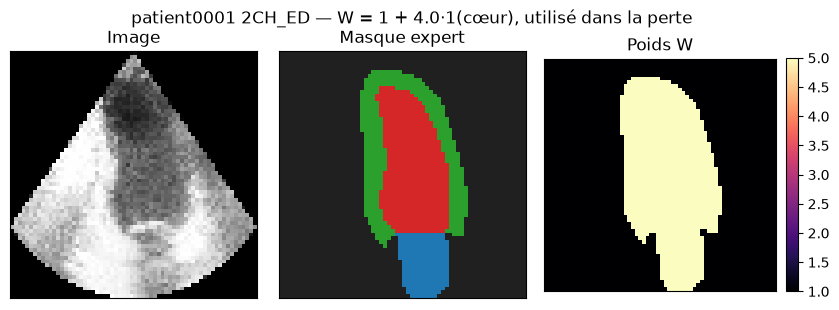

In [9]:
BETA_MAX = 1e-5
WARMUP_EPOCHS = 20
GAMMA = 0.025
DELTA = 2.0
MSE_WEIGHT = 0.35
L1_WEIGHT = 0.25
SSIM_WEIGHT = 0.25
GRAD_WEIGHT = 0.10
FFT_WEIGHT = 0.05
HEART_WEIGHT = 4.0
LR = 8e-4
WEIGHT_DECAY = 1e-5
ETA_MIN = 5e-6
EMA_DECAY = 0.995
N_EPOCHS = int(os.environ.get("CAMUS_EXP6_EPOCHS", "150"))
TRAIN = os.environ.get("CAMUS_EXP6_TRAIN", "1") not in {"0", "false", "False"}

ssim_loss = SSIMLoss(spatial_dims=2, data_range=1.0, win_size=7).to(device)


def beta_at(epoch):
    # Époque 1 : 0. Époque 20 et suivantes : BETA_MAX.
    progress = (epoch - 1) / (WARMUP_EPOCHS - 1)
    return BETA_MAX * min(1.0, max(0.0, progress))


def kl_divergence(mu, sigma):
    sigma = sigma.clamp_min(1e-6)
    kl = 0.5 * torch.sum(
        mu.pow(2) + sigma.pow(2) - torch.log(sigma.pow(2)) - 1,
        dim=tuple(range(1, mu.ndim)),
    )
    return kl.mean()


def attribute_loss(channel, area):
    # channel : μ[:, k], grille spatiale. La cible est la moyenne a posteriori.
    z = channel.mean(dim=(1, 2))
    if z.shape[0] < 2:
        return z.new_zeros(())
    diff_z = z[:, None] - z[None, :]
    diff_a = area[:, None] - area[None, :]
    eye = torch.eye(z.shape[0], dtype=torch.bool, device=z.device)
    residual = torch.tanh(DELTA * diff_z) - torch.sign(diff_a)
    return residual.abs()[~eye].mean()


def weighted_gradient_l1(recon, image, weights):
    dx_recon = recon[:, :, :, 1:] - recon[:, :, :, :-1]
    dx_image = image[:, :, :, 1:] - image[:, :, :, :-1]
    dy_recon = recon[:, :, 1:, :] - recon[:, :, :-1, :]
    dy_image = image[:, :, 1:, :] - image[:, :, :-1, :]
    weight_x = torch.maximum(weights[:, :, :, 1:], weights[:, :, :, :-1])
    weight_y = torch.maximum(weights[:, :, 1:, :], weights[:, :, :-1, :])
    numerator = (weight_x * (dx_recon - dx_image).abs()).sum()
    numerator = numerator + (weight_y * (dy_recon - dy_image).abs()).sum()
    denominator = (weight_x.sum() + weight_y.sum()).clamp_min(1.0)
    return numerator / denominator


def compute_UltraFidelity_loss(recon, image, label, mu, sigma, beta):
    weights = 1.0 + HEART_WEIGHT * (label > 0).to(dtype=recon.dtype).unsqueeze(1)
    error = recon - image
    denom = weights.sum().clamp_min(1.0)
    mse_w = (weights * error.pow(2)).sum() / denom
    l1_w = (weights * error.abs()).sum() / denom
    ssim_64 = 1.0 - ssim_loss(recon, image)
    recon_32 = F.avg_pool2d(recon, kernel_size=2, stride=2)
    image_32 = F.avg_pool2d(image, kernel_size=2, stride=2)
    ssim_32 = 1.0 - ssim_loss(recon_32, image_32)
    ssim_term = 0.7 * (1.0 - ssim_64) + 0.3 * (1.0 - ssim_32)
    grad_l1_w = weighted_gradient_l1(recon, image, weights)
    fft_recon = torch.fft.rfft2(recon, norm="ortho")
    fft_image = torch.fft.rfft2(image, norm="ortho")
    fft_loss = F.l1_loss(torch.abs(fft_recon), torch.abs(fft_image))
    recon_loss = (
        MSE_WEIGHT * mse_w
        + L1_WEIGHT * l1_w
        + SSIM_WEIGHT * ssim_term
        + GRAD_WEIGHT * grad_l1_w
        + FFT_WEIGHT * fft_loss
    )
    kl_loss = kl_divergence(mu, sigma)
    areas = (
        (label == 1).to(dtype=mu.dtype).mean(dim=(1, 2)),
        (label == 2).to(dtype=mu.dtype).mean(dim=(1, 2)),
        (label == 3).to(dtype=mu.dtype).mean(dim=(1, 2)),
    )
    attr_terms = [attribute_loss(mu[:, channel], area) for channel, area in enumerate(areas)]
    attr = torch.stack(attr_terms).mean()
    total = recon_loss + beta * kl_loss + GAMMA * attr
    mse = error.pow(2).mean()
    return (
        total,
        recon_loss.detach(),
        mse.detach(),
        kl_loss.detach(),
        attr.detach(),
        ssim_64.detach(),
        grad_l1_w.detach(),
        fft_loss.detach(),
    )


print(
    f"β max = {BETA_MAX:.0e}   γ = {GAMMA:.3f}   δ = {DELTA:.1f}   "
    f"époques = {N_EPOCHS}   TRAIN = {TRAIN}   EMA = {EMA_DECAY}"
)
print(
    "Reconstruction = "
    f"{MSE_WEIGHT:.2f} MSE_w + {L1_WEIGHT:.2f} L1_w + "
    f"{SSIM_WEIGHT:.2f} SSIM_ms + {GRAD_WEIGHT:.2f} grad_w + {FFT_WEIGHT:.2f} FFT"
)
print("Calendrier de β :")
for epoch in (1, 2, 5, 20, 21):
    print(f"  époque {epoch:02d}  β = {beta_at(epoch):.3e}")

example = train_dataset[0]
label_np = example["label"].numpy()
weight_np = 1.0 + HEART_WEIGHT * (label_np > 0).astype(np.float32)
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.1))
axes[0].imshow(example["image"][0].numpy(), cmap="gray", vmin=0, vmax=1)
axes[1].imshow(label_np, cmap=HEART_CMAP, vmin=0, vmax=3, interpolation="nearest")
weight_image = axes[2].imshow(weight_np, cmap="magma", vmin=1, vmax=1.0 + HEART_WEIGHT)
axes[0].set_title("Image")
axes[1].set_title("Masque expert")
axes[2].set_title("Poids W")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(weight_image, ax=axes[2], fraction=0.046, pad=0.04)
fig.suptitle(
    f"{example['patient']} {example['view_instant']} — "
    f"W = 1 + {HEART_WEIGHT:.1f}·1(cœur), utilisé dans la perte"
)
fig.tight_layout()
plt.show()


In [10]:
CONFIG = {
    "spatial_dims": 2,
    "in_channels": IN_CHANNELS,
    "out_channels": 1,
    "channels": list(CHANNELS),
    "attention_levels": list(ATTENTION_LEVELS),
    "latent_channels": LATENT_CHANNELS,
    "latent_shape": list(LATENT_SHAPE),
    "norm_num_groups": NORM_GROUPS,
    "num_res_blocks": NUM_RES_BLOCKS,
    "beta_max": BETA_MAX,
    "warmup_epochs": WARMUP_EPOCHS,
    "gamma": GAMMA,
    "delta": DELTA,
    "recon_mse_weight": MSE_WEIGHT,
    "recon_l1_weight": L1_WEIGHT,
    "recon_ssim_weight": SSIM_WEIGHT,
    "recon_grad_weight": GRAD_WEIGHT,
    "recon_fft_weight": FFT_WEIGHT,
    "heart_weight": HEART_WEIGHT,
    "ema_decay": EMA_DECAY,
    "supervised_channels": [0, 1, 2],
    "recon_loss": "0.35*mse_w+0.25*l1_w+0.25*ms_ssim+0.10*grad_l1_w+0.05*fft",
    "image_size": IMAGE_SIZE,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "eta_min": ETA_MIN,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "precision": "fp32",
    "epochs": N_EPOCHS,
    "device": gpu_name,
}

LOSS_KEYS = ("total", "recon", "mse", "ssim", "kl", "attr", "grad", "fft")


def preload_split(dataset):
    images = torch.stack([record["image"] for record in dataset.records]).contiguous()
    labels = torch.stack([record["label"] for record in dataset.records]).contiguous()
    return images.to(device), labels.to(device)


def iter_gpu_batches(images, labels, batch_size, shuffle):
    count = images.shape[0]
    if shuffle:
        order = torch.randperm(count, device=images.device)
    else:
        order = torch.arange(count, device=images.device)
    for start in range(0, count, batch_size):
        index = order[start:start + batch_size]
        yield images.index_select(0, index), labels.index_select(0, index)


def empty_sums():
    return {key: torch.zeros((), device=device) for key in LOSS_KEYS}


ema_box = {"state": None}


def clone_state(module):
    return {key: value.detach().clone() for key, value in module.state_dict().items()}


def ema_update():
    state = ema_box["state"]
    with torch.no_grad():
        for key, value in model.state_dict().items():
            if value.dtype.is_floating_point:
                state[key].mul_(EMA_DECAY).add_(value.detach(), alpha=1.0 - EMA_DECAY)
            else:
                state[key].copy_(value)


def accumulate_split(images, labels, beta, train, update_ema=False):
    sums = empty_sums()
    nonfinite = torch.zeros((), dtype=torch.float32, device=device)
    seen = 0
    for batch_images, batch_labels in iter_gpu_batches(images, labels, BATCH_SIZE, shuffle=train):
        if train:
            optimizer.zero_grad(set_to_none=True)
        mu, sigma = model.encode(batch_images)
        # Entraînement : échantillon. Évaluation : μ, mode a posteriori.
        latent = model.sampling(mu, sigma) if train else mu
        recon = decode_image(model, latent)
        total, recon_loss, mse, kl_loss, attr, ssim_val, grad_l1, fft_loss = compute_UltraFidelity_loss(
            recon, batch_images, batch_labels, mu, sigma, beta,
        )
        if train:
            total.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            if update_ema:
                ema_update()
        scale = total.new_tensor(float(batch_images.shape[0]))
        sums["total"] = sums["total"] + total.detach() * scale
        sums["recon"] = sums["recon"] + recon_loss * scale
        sums["mse"] = sums["mse"] + mse * scale
        sums["ssim"] = sums["ssim"] + ssim_val * scale
        sums["kl"] = sums["kl"] + kl_loss * scale
        sums["attr"] = sums["attr"] + attr * scale
        sums["grad"] = sums["grad"] + grad_l1 * scale
        sums["fft"] = sums["fft"] + fft_loss * scale
        nonfinite = nonfinite + (~torch.isfinite(total.detach())).to(dtype=torch.float32)
        seen += int(batch_images.shape[0])
    payload = torch.stack([sums[key] / seen for key in LOSS_KEYS] + [nonfinite])
    values = payload.detach().cpu().tolist()
    return dict(zip(LOSS_KEYS, values[:-1])), values[-1] != 0.0


def train_vae(model, n_epochs, config, lr=LR):
    global optimizer
    set_seed(SEED)
    train_images, train_labels = preload_split(train_dataset)
    valid_images, valid_labels = preload_split(valid_dataset)
    print(
        f"Préchargement VRAM : train {tuple(train_images.shape)}, "
        f"val {tuple(valid_images.shape)}, "
        f"{torch.cuda.memory_allocated() / 1024 ** 2:.0f} Mo alloués"
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(n_epochs, 1), eta_min=ETA_MIN,
    )
    history = {
        key: []
        for key in (
            "train_total", "train_recon", "train_mse", "train_ssim", "train_kl", "train_attr", "train_grad", "train_fft",
            "val_total", "val_recon", "val_mse", "val_ssim", "val_kl", "val_attr", "val_grad", "val_fft",
            "beta", "lr",
        )
    }
    history.update({
        "beta_max": BETA_MAX,
        "gamma": GAMMA,
        "delta": DELTA,
        "epochs": n_epochs,
        "warmup_epochs": WARMUP_EPOCHS,
        "recon": CONFIG["recon_loss"],
        "selection": "ema_val_recon",
        "ema_decay": EMA_DECAY,
    })
    best_score = float("inf")
    best_state = None
    best_epoch = 0
    torch.cuda.reset_peak_memory_stats()
    clock = time.perf_counter()
    log_path = ARTIFACT_DIR / "exp6_train.log"
    log_file = log_path.open("w", encoding="utf-8")
    print(
        f"Sélection sur la reconstruction EMA de validation à partir de l'époque {WARMUP_EPOCHS}. "
        f"L'EMA (decay {EMA_DECAY}) est copiée à la fin de l'époque {WARMUP_EPOCHS - 1}, "
        f"puis mise à jour après chaque pas. Journal : {log_path}. "
        f"Le fichier .pth est écrit une seule fois à la fin."
    )

    for epoch in range(n_epochs):
        beta = beta_at(epoch + 1)
        lr_now = float(optimizer.param_groups[0]["lr"])
        model.train()
        update_ema = ema_box["state"] is not None and (epoch + 1) >= WARMUP_EPOCHS
        train_means, train_bad = accumulate_split(
            train_images, train_labels, beta, train=True, update_ema=update_ema,
        )
        if train_bad:
            raise RuntimeError(f"Perte d'entraînement non finie à l'époque {epoch + 1}")
        model.eval()
        validate_with_ema = ema_box["state"] is not None and (epoch + 1) >= WARMUP_EPOCHS
        live_state = clone_state(model) if validate_with_ema else None
        if validate_with_ema:
            model.load_state_dict(ema_box["state"])
        with torch.no_grad():
            val_means, val_bad = accumulate_split(valid_images, valid_labels, beta, train=False)
        if validate_with_ema:
            model.load_state_dict(live_state)
        if val_bad:
            raise RuntimeError(f"Perte de validation non finie à l'époque {epoch + 1}")
        if (epoch + 1) == WARMUP_EPOCHS - 1:
            ema_box["state"] = clone_state(model)

        for key in LOSS_KEYS:
            history[f"train_{key}"].append(train_means[key])
            history[f"val_{key}"].append(val_means[key])
        history["beta"].append(beta)
        history["lr"].append(lr_now)

        saved = False
        if (epoch + 1) >= WARMUP_EPOCHS and val_means["recon"] < best_score:
            best_score = val_means["recon"]
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in ema_box["state"].items()
            }
            history["best_epoch"] = best_epoch
            history["best_val"] = best_score
            saved = True

        flag = "  meilleur val_recon EMA" if saved else ""
        line = (
            f"Époque {epoch + 1:02d}/{n_epochs}  "
            f"β={beta:.2e}  lr={lr_now:.2e}  "
            f"train {train_means['total']:.5f} "
            f"(recon {train_means['recon']:.5f}, mse {train_means['mse']:.5f}, "
            f"ssim {train_means['ssim']:.3f}, grad {train_means['grad']:.5f}, "
            f"fft {train_means['fft']:.5f}, "
            f"kl {train_means['kl']:.2f}, attr {train_means['attr']:.4f})  "
            f"val {val_means['total']:.5f} "
            f"(recon {val_means['recon']:.5f}, mse {val_means['mse']:.5f}, "
            f"ssim {val_means['ssim']:.3f}, grad {val_means['grad']:.5f}, "
            f"fft {val_means['fft']:.5f}, "
            f"kl {val_means['kl']:.2f}, attr {val_means['attr']:.4f})"
            f"{flag}"
        )
        print(line, flush=True)
        log_file.write(line + "\n")
        log_file.flush()
        scheduler.step()

    history["seconds"] = time.perf_counter() - clock
    history["best_epoch"] = best_epoch
    history["best_val"] = best_score
    history["max_memory_mb"] = torch.cuda.max_memory_allocated() / (1024 ** 2)
    if best_state is None:
        raise RuntimeError("Aucun checkpoint : la sélection n'a retenu aucune époque.")
    model.load_state_dict(best_state)
    torch.save(
        {
            "state_dict": best_state,
            "epoch": best_epoch,
            "history": history,
            "config": config,
        },
        CHECKPOINT_PATH,
    )
    log_file.write(
        f"Meilleure époque {best_epoch}/{n_epochs}, "
        f"reconstruction de validation {best_score:.6f}, "
        f"durée {history['seconds'] / 60:.2f} min, "
        f"VRAM crête {history['max_memory_mb']:.0f} Mo.\n"
    )
    log_file.close()
    print(
        f"Meilleure époque {best_epoch}/{n_epochs}, "
        f"reconstruction de validation {best_score:.6f}, "
        f"durée {history['seconds'] / 60:.2f} min, "
        f"VRAM crête {history['max_memory_mb']:.0f} Mo."
    )
    print(f"Poids enregistrés dans {CHECKPOINT_PATH}.")
    return model, history


model = build_vae(SEED)
if TRAIN:
    model, history = train_vae(model, N_EPOCHS, CONFIG, lr=LR)
else:
    if not CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(f"Checkpoint absent : {CHECKPOINT_PATH}")
    payload = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
    model.load_state_dict(payload["state_dict"])
    history = payload["history"]
    print(f"Poids rechargés : {CHECKPOINT_PATH} (époque {history['best_epoch']})")


Préchargement VRAM : train (1600, 1, 64, 64), val (200, 1, 64, 64), 496 Mo alloués
Sélection sur la reconstruction EMA de validation à partir de l'époque 20. L'EMA (decay 0.995) est copiée à la fin de l'époque 19, puis mise à jour après chaque pas. Journal : artifacts\exp6_train.log. Le fichier .pth est écrit une seule fois à la fin.


Époque 01/150  β=0.00e+00  lr=8.00e-04  train 0.30989 (recon 0.28499, mse 0.06538, ssim 0.187, grad 0.06389, fft 0.07392, kl 17812366.00, attr 0.9960)  val 0.27878 (recon 0.25425, mse 0.03729, ssim 0.234, grad 0.05870, fft 0.06763, kl 3017435.50, attr 0.9814)


Époque 02/150  β=5.26e-07  lr=8.00e-04  train 0.29438 (recon 0.23462, mse 0.03930, ssim 0.304, grad 0.06214, fft 0.06761, kl 66234.37, attr 0.9959)  val 0.21984 (recon 0.19118, mse 0.02541, ssim 0.413, grad 0.05916, fft 0.06138, kl 7153.79, attr 0.9955)


Époque 03/150  β=1.05e-06  lr=8.00e-04  train 0.23486 (recon 0.20398, mse 0.03218, ssim 0.398, grad 0.06147, fft 0.06496, kl 5799.52, attr 0.9911)  val 0.25777 (recon 0.22475, mse 0.04176, ssim 0.385, grad 0.06123, fft 0.06491, kl 7745.39, attr 0.9944)


Époque 04/150  β=1.58e-06  lr=7.99e-04  train 0.25323 (recon 0.21832, mse 0.04224, ssim 0.387, grad 0.06292, fft 0.06850, kl 6434.00, attr 0.9900)  val 0.35250 (recon 0.31817, mse 0.12916, ssim 0.342, grad 0.06623, fft 0.08141, kl 5999.72, attr 0.9942)


Époque 05/150  β=2.11e-06  lr=7.99e-04  train 0.25721 (recon 0.21832, mse 0.04418, ssim 0.389, grad 0.06254, fft 0.07180, kl 6727.42, attr 0.9893)  val 0.27262 (recon 0.23985, mse 0.04599, ssim 0.332, grad 0.05862, fft 0.07429, kl 3805.08, attr 0.9903)


... (142 outputs left out)

Époque 148/150  β=1.00e-05  lr=5.78e-06  train 0.12044 (recon 0.09072, mse 0.00611, ssim 0.685, grad 0.05606, fft 0.04727, kl 571.29, attr 0.9603)  val 0.11531 (recon 0.08659, mse 0.00534, ssim 0.694, grad 0.05408, fft 0.04541, kl 568.13, attr 0.9218)  meilleur val_recon EMA


Époque 149/150  β=1.00e-05  lr=5.35e-06  train 0.12040 (recon 0.09067, mse 0.00610, ssim 0.685, grad 0.05604, fft 0.04725, kl 571.77, attr 0.9608)  val 0.11529 (recon 0.08656, mse 0.00534, ssim 0.694, grad 0.05408, fft 0.04540, kl 568.52, attr 0.9217)  meilleur val_recon EMA


Époque 150/150  β=1.00e-05  lr=5.09e-06  train 0.12038 (recon 0.09066, mse 0.00608, ssim 0.684, grad 0.05603, fft 0.04726, kl 571.70, attr 0.9600)  val 0.11527 (recon 0.08654, mse 0.00533, ssim 0.694, grad 0.05408, fft 0.04539, kl 568.81, attr 0.9217)  meilleur val_recon EMA


Meilleure époque 150/150, reconstruction de validation 0.086538, durée 39.27 min, VRAM crête 5781 Mo.
Poids enregistrés dans checkpoints\exp6_vae_best.pth.


### Courbes

La courbe de SSIM est le SSIM pleine résolution, fenêtre 7. Le terme optimisé mélange aussi le SSIM à 32×32. La MSE tracée est la MSE brute, celle des tableaux de test. La courbe de gradient est la L1 pondérée des différences finies. L'amplitude FFT est dans le journal d'époque, pas sur ces six panneaux.


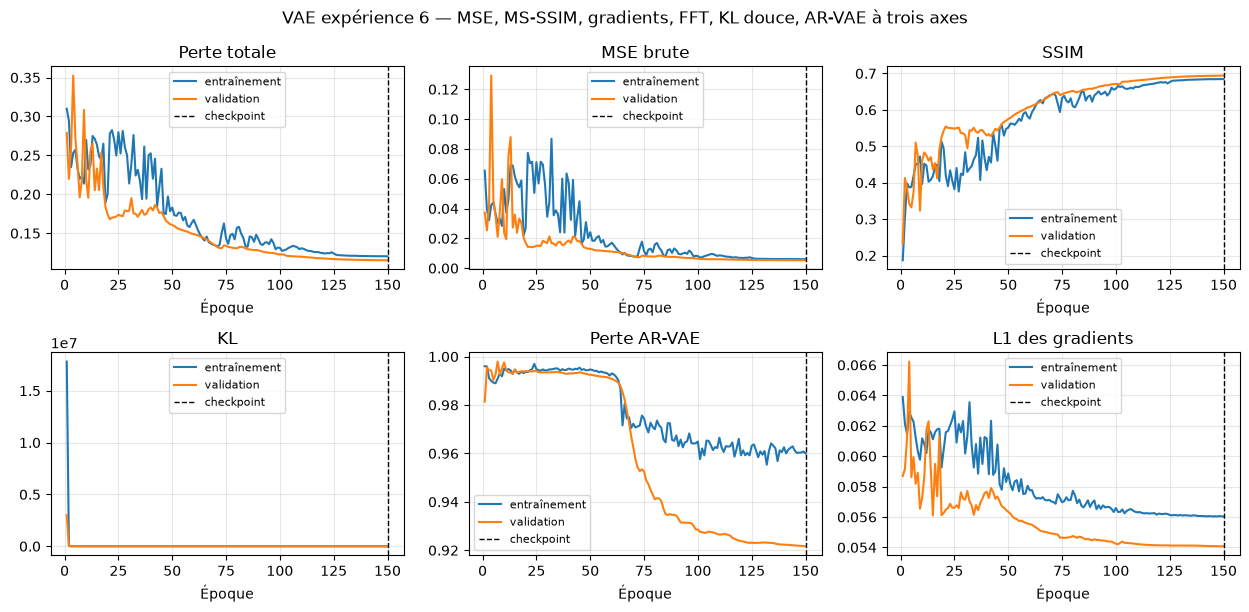

In [11]:
def plot_history(history):
    epochs = np.arange(1, len(history["train_total"]) + 1)
    fig, axes = plt.subplots(2, 3, figsize=(12.6, 6.2))
    series = (
        ("total", "Perte totale"),
        ("mse", "MSE brute"),
        ("ssim", "SSIM"),
        ("kl", "KL"),
        ("attr", "Perte AR-VAE"),
        ("grad", "L1 des gradients"),
    )
    for ax, (key, title) in zip(axes.ravel(), series):
        ax.plot(epochs, history[f"train_{key}"], label="entraînement")
        ax.plot(epochs, history[f"val_{key}"], label="validation")
        ax.axvline(history["best_epoch"], color="black", ls="--", lw=1, label="checkpoint")
        ax.set_title(title)
        ax.set_xlabel("Époque")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle("VAE expérience 6 — MSE, MS-SSIM, gradients, FFT, KL douce, AR-VAE à trois axes")
    fig.tight_layout()
    plt.show()


plot_history(history)


## 4. Évaluation

Les métriques de test décodent μ. La MSE, la MAE, le PSNR et le SSIM utilisent les mêmes définitions que les expériences 1 à 3 : PSNR avec `max_val` 1, SSIM de MONAI avec une fenêtre de 7. La MSE cœur moyenne l'erreur quadratique sur les pixels `label > 0`. La MSE fond fait de même sur `label == 0`. Le PSNR cœur est `10 log10(1 / MSE cœur)` sur chaque image, puis moyenné.


Poids rechargés : époque 150, reconstruction de validation 0.086538, durée 39.27 min.


MSE moyenne sur les 200 images de test : 0.00609 ± 0.00281
MAE test :  0.042 ± 0.009
PSNR test : 22.49 ± 1.63 dB
SSIM test : 0.682 ± 0.033
MSE sur le cœur : 0.00842 ± 0.00315
MSE sur le fond : 0.00539 ± 0.00300
PSNR sur le cœur : 21.00 ± 1.46 dB


### MSE, PSNR et SSIM de test par vue et par instant

| Vue / instant | n | MSE | PSNR (dB) | SSIM |
| --- | --- | --- | --- | --- |
| 2CH_ED | 50 | 0.00593 | 22.54 | 0.685 |
| 2CH_ES | 50 | 0.00540 | 23.03 | 0.684 |
| 4CH_ED | 50 | 0.00684 | 21.97 | 0.680 |
| 4CH_ES | 50 | 0.00619 | 22.42 | 0.681 |

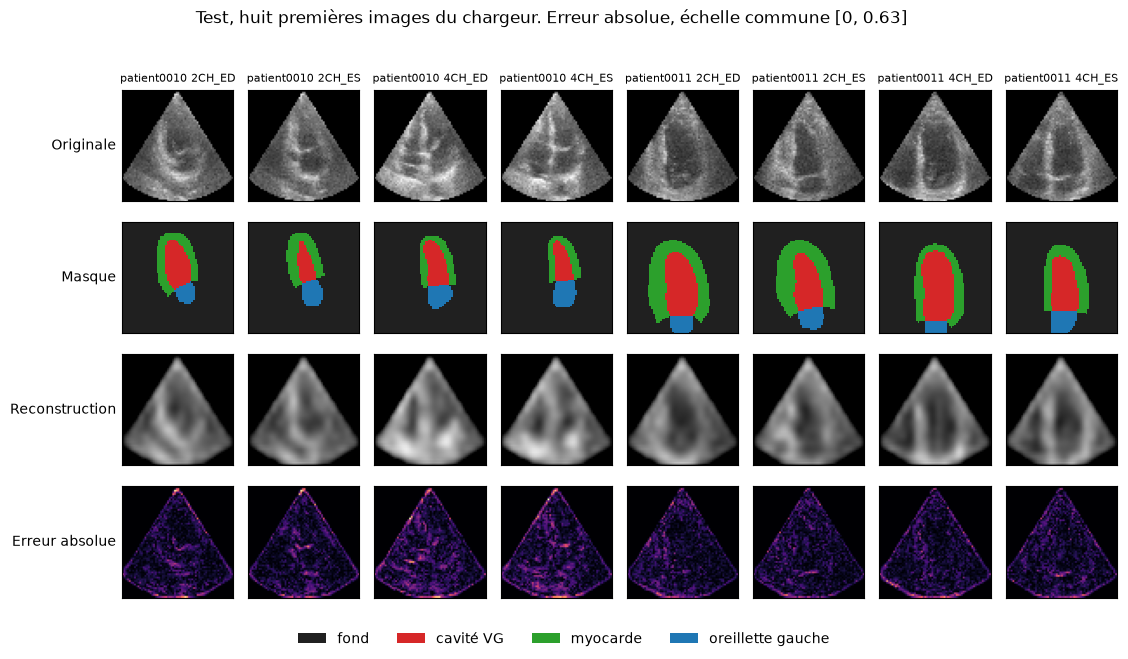

In [12]:
def make_ssim():
    return SSIMMetric(spatial_dims=2, data_range=1.0, win_size=7, reduction="none")


def reconstruction_scores(recon, target):
    error = recon - target
    mae = error.abs().mean(dim=(1, 2, 3)).detach().cpu().numpy()
    mse = error.pow(2).mean(dim=(1, 2, 3)).detach().cpu().numpy()
    psnr = PSNRMetric(max_val=1.0, reduction="none")(recon, target).detach().cpu().numpy().reshape(-1)
    ssim = make_ssim()(recon.clamp(0, 1), target.clamp(0, 1)).detach().cpu().numpy().reshape(-1)
    return mae, mse, psnr, ssim


def mean_std(values):
    values = np.asarray(values, dtype=np.float64)
    return float(np.mean(values)), float(np.std(values))


def fmt_mean_std(values, digits=3):
    mu, sigma = mean_std(values)
    return f"{mu:.{digits}f} ± {sigma:.{digits}f}"


def fmt_pm(mean, std, digits):
    if mean is None:
        return "n.d."
    if std is None:
        return f"{mean:.{digits}f}"
    return f"{mean:.{digits}f} ± {std:.{digits}f}"


def fmt_int(value):
    if value is None:
        return "n.d."
    return f"{int(value):,}".replace(",", " ")


def masked_mse(recon, image, label, inside):
    error = (recon - image).pow(2)
    mask = (label.unsqueeze(1) > 0) if inside else (label.unsqueeze(1) == 0)
    mask = mask.to(error.dtype)
    denom = mask.sum(dim=(1, 2, 3)).clamp_min(1)
    return ((error * mask).sum(dim=(1, 2, 3)) / denom).detach().cpu().numpy()


def as_float_vector(value):
    if torch.is_tensor(value):
        return value.detach().cpu().float().reshape(-1)
    return torch.tensor(value, dtype=torch.float32).reshape(-1)


@torch.no_grad()
def collect_predictions(net, loader):
    net.eval()
    images, recons, labels, mus, areas = [], [], [], [], []
    epi_areas, la_areas = [], []
    view_instants, views, instants, patients = [], [], [], []
    for batch in loader:
        x = batch["image"].to(device, non_blocking=True)
        mu, sigma = net.encode(x)
        recon = decode_image(net, mu)
        images.append(batch["image"])
        recons.append(recon.cpu())
        labels.append(batch["label"])
        mus.append(mu.cpu())
        areas.append(as_float_vector(batch["lv_area"]))
        epi_areas.append(as_float_vector(batch["epi_area"]))
        la_areas.append(as_float_vector(batch["la_area"]))
        view_instants.extend(list(batch["view_instant"]))
        views.extend(list(batch["view"]))
        instants.extend(list(batch["instant"]))
        patients.extend(list(batch["patient"]))
    packed = {
        "image": torch.cat(images),
        "recon": torch.cat(recons),
        "label": torch.cat(labels),
        "mu": torch.cat(mus),
        "lv_area": torch.cat(areas).numpy(),
        "epi_area": torch.cat(epi_areas).numpy(),
        "la_area": torch.cat(la_areas).numpy(),
        "view_instant": np.asarray(view_instants),
        "view": np.asarray(views),
        "instant": np.asarray(instants),
        "patient": np.asarray(patients),
    }
    mae, mse, psnr, ssim = reconstruction_scores(packed["recon"], packed["image"])
    packed.update({"mae": mae, "mse": mse, "psnr": psnr, "ssim": ssim})
    return packed


def markdown_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
    ]
    for row in rows:
        lines.append("| " + " | ".join(str(cell) for cell in row) + " |")
    return "\n".join(lines)


if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Checkpoint absent : {CHECKPOINT_PATH}")
payload = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
saved_config = payload["config"]
assert tuple(saved_config["channels"]) == tuple(CHANNELS)
assert saved_config["latent_channels"] == LATENT_CHANNELS
assert saved_config["num_res_blocks"] == NUM_RES_BLOCKS
model.load_state_dict(payload["state_dict"])
history = payload["history"]
model.eval()
print(
    f"Poids rechargés : époque {payload['epoch']}, "
    f"reconstruction de validation {history['best_val']:.6f}, "
    f"durée {history['seconds'] / 60:.2f} min."
)

test_pred = collect_predictions(model, test_loader)
assert len(test_pred["mse"]) == len(test_dataset) == 200
heart_mse = masked_mse(test_pred["recon"], test_pred["image"], test_pred["label"], inside=True)
background_mse = masked_mse(test_pred["recon"], test_pred["image"], test_pred["label"], inside=False)

print(f"MSE moyenne sur les {len(test_dataset)} images de test : {fmt_mean_std(test_pred['mse'], digits=5)}")
print(f"MAE test :  {fmt_mean_std(test_pred['mae'])}")
print(f"PSNR test : {fmt_mean_std(test_pred['psnr'], digits=2)} dB")
print(f"SSIM test : {fmt_mean_std(test_pred['ssim'])}")
print(f"MSE sur le cœur : {fmt_mean_std(heart_mse, digits=5)}")
heart_psnr = -10.0 * np.log10(np.clip(heart_mse, 1e-12, None))
print(f"MSE sur le fond : {fmt_mean_std(background_mse, digits=5)}")
print(f"PSNR sur le cœur : {fmt_mean_std(heart_psnr, digits=2)} dB")

per_class_rows = []
per_view_instant = {}
for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    mse_mean, mse_std = mean_std(test_pred["mse"][selected])
    psnr_mean, psnr_std = mean_std(test_pred["psnr"][selected])
    ssim_mean, ssim_std = mean_std(test_pred["ssim"][selected])
    per_class_rows.append([
        view_instant,
        int(selected.sum()),
        f"{mse_mean:.5f}",
        f"{psnr_mean:.2f}",
        f"{ssim_mean:.3f}",
    ])
    per_view_instant[view_instant] = {
        "n": int(selected.sum()),
        "mse_mean": mse_mean,
        "mse_std": mse_std,
        "psnr_mean": psnr_mean,
        "psnr_std": psnr_std,
        "ssim_mean": ssim_mean,
        "ssim_std": ssim_std,
    }

display(Markdown(
    "### MSE, PSNR et SSIM de test par vue et par instant\n\n"
    + markdown_table(["Vue / instant", "n", "MSE", "PSNR (dB)", "SSIM"], per_class_rows)
))

n_show = 8
shown_error = (test_pred["recon"][:n_show] - test_pred["image"][:n_show]).abs()
error_vmax = float(shown_error.max().clamp_min(1e-3))
fig, axes = plt.subplots(4, n_show, figsize=(1.45 * n_show, 6.6))
row_names = ("Originale", "Masque", "Reconstruction", "Erreur absolue")
for index in range(n_show):
    axes[0, index].imshow(test_pred["image"][index, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[1, index].imshow(
        test_pred["label"][index].numpy(),
        cmap=HEART_CMAP,
        vmin=0,
        vmax=3,
        interpolation="nearest",
    )
    axes[2, index].imshow(test_pred["recon"][index, 0].clamp(0, 1).numpy(), cmap="gray", vmin=0, vmax=1)
    axes[3, index].imshow(shown_error[index, 0].numpy(), cmap="magma", vmin=0, vmax=error_vmax)
    axes[0, index].set_title(
        f"{test_pred['patient'][index]} {test_pred['view_instant'][index]}",
        fontsize=8,
    )
    for row in range(4):
        axes[row, index].set_xticks([])
        axes[row, index].set_yticks([])
for row, name in enumerate(row_names):
    axes[row, 0].set_ylabel(name, rotation=0, ha="right", va="center")
legend = [
    Patch(facecolor=HEART_CMAP(index / 3), edgecolor="none", label=LABEL_NAMES[index])
    for index in range(4)
]
fig.legend(handles=legend, loc="lower center", ncol=4, frameon=False)
fig.suptitle(
    f"Test, huit premières images du chargeur. Erreur absolue, échelle commune [0, {error_vmax:.2f}]"
)
fig.tight_layout(rect=(0.02, 0.05, 1, 0.96))
plt.show()


### Analyse de Fidélité & Cartes d'Erreur

Quatre cadres de test, un par couple vue / instant. De gauche à droite : l'image originale, la reconstruction avec les contours expert (cavité en rouge, myocarde en vert, oreillette en bleu), l'erreur absolue amplifiée cinq fois, et le profil d'intensité sur la ligne du centroïde de la cavité ventriculaire gauche. La ligne cyan marque cette coupe.


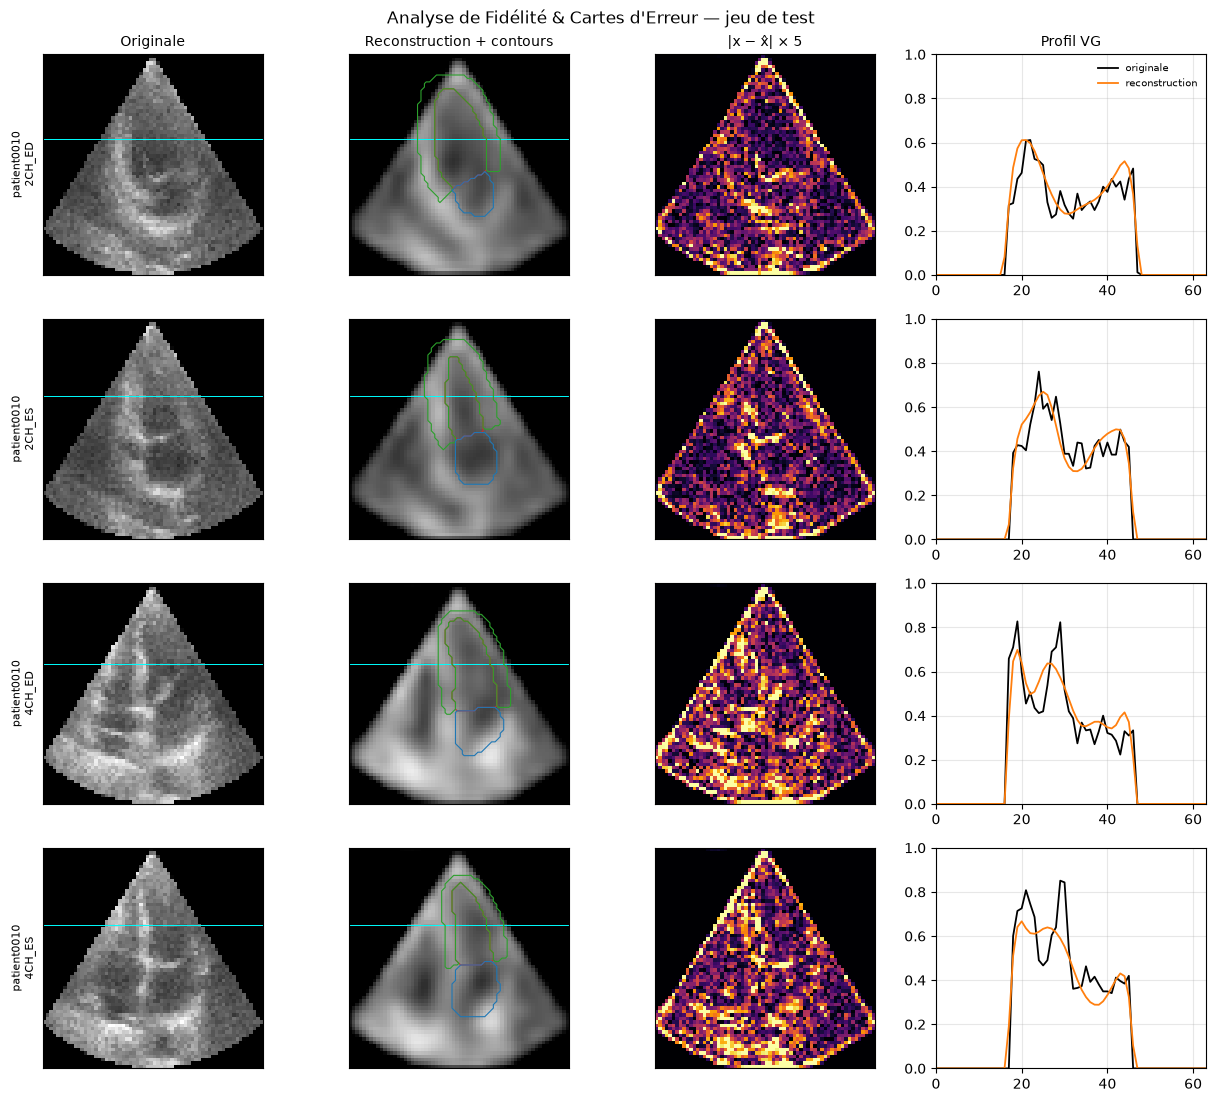

In [13]:
def lv_cut_row(label):
    cavity = label == 1
    if not cavity.any():
        return int(label.shape[0] // 2)
    rows = np.flatnonzero(cavity.any(axis=1))
    return int(round(rows.mean()))


contour_colors = {1: "#d62728", 2: "#2ca02c", 3: "#1f77b4"}
fidelity_index = []
for view_instant in VIEWS:
    matches = np.flatnonzero(test_pred["view_instant"] == view_instant)
    if len(matches) == 0:
        raise RuntimeError(f"Aucun cadre de test pour {view_instant}.")
    fidelity_index.append(int(matches[0]))

fig, axes = plt.subplots(len(fidelity_index), 4, figsize=(12.4, 11.2))
column_names = ("Originale", "Reconstruction + contours", "|x − x̂| × 5", "Profil VG")
for row, index in enumerate(fidelity_index):
    image = test_pred["image"][index, 0].numpy()
    recon = test_pred["recon"][index, 0].clamp(0, 1).numpy()
    label = test_pred["label"][index].numpy()
    cut = lv_cut_row(label)
    axes[row, 0].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[row, 0].axhline(cut, color="cyan", lw=0.7)
    axes[row, 1].imshow(recon, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].axhline(cut, color="cyan", lw=0.7)
    for class_id, color in contour_colors.items():
        if np.any(label == class_id):
            axes[row, 1].contour(
                (label == class_id).astype(np.float32),
                levels=[0.5],
                colors=[color],
                linewidths=0.8,
            )
    axes[row, 2].imshow(np.abs(image - recon) * 5.0, cmap="inferno", vmin=0, vmax=1)
    axes[row, 3].plot(image[cut], color="black", lw=1.3, label="originale")
    axes[row, 3].plot(recon[cut], color="tab:orange", lw=1.3, label="reconstruction")
    axes[row, 3].set_xlim(0, image.shape[1] - 1)
    axes[row, 3].set_ylim(0, 1)
    axes[row, 3].grid(True, alpha=0.3)
    axes[row, 0].set_ylabel(
        f"{test_pred['patient'][index]}\n{test_pred['view_instant'][index]}",
        fontsize=8,
    )
    for column in range(3):
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
for column, name in enumerate(column_names):
    axes[0, column].set_title(name, fontsize=10)
axes[0, 3].legend(frameon=False, fontsize=7)
fig.suptitle("Analyse de Fidélité & Cartes d'Erreur — jeu de test")
fig.tight_layout()
plt.show()


### Comparaison des six expériences

Les fichiers `artifacts/results_exp2.json`, `artifacts/results_exp3.json`, `artifacts/results_exp4.json` et `artifacts/results_exp5.json` sont relus lorsqu'ils sont présents. Sinon, le tableau reprend les chiffres imprimés par les notebooks déjà exécutés. Les expériences 4 et 5 viennent de leurs JSON. L'expérience 6 est le passage en cours. Une valeur en gras est la meilleure de la ligne : plus basse pour les erreurs et les durées, plus haute pour le PSNR, le SSIM et le Spearman. Les Spearman de `z1` et `z2` ne sont renseignés que pour l'expérience 6 : les expériences précédentes ne supervisaient pas ces axes.


In [14]:
PUBLISHED = {
    "1": {
        "name": "Expérience 1",
        "hardware": "CPU",
        "latent": "4×8×8",
        "n_params": 473_649,
        "epochs": 25,
        "best_epoch": 25,
        "seconds": 26.8 * 60,
        "mse": 0.01024,
        "mse_std": 0.01093,
        "mae": 0.057,
        "mae_std": 0.026,
        "psnr": 20.97,
        "psnr_std": 2.68,
        "ssim": 0.622,
        "ssim_std": 0.070,
        "heart_mse": 0.01511,
        "heart_mse_std": 0.01215,
        "background_mse": 0.00871,
        "background_mse_std": 0.01079,
        "spearman": None,
        "source": "tableau exécuté de exp_3_vae_camus.ipynb (VAE final, 25 époques)",
    },
    "2": {
        "name": "Expérience 2",
        "hardware": "CPU",
        "latent": "8×8×8",
        "n_params": 1_888_449,
        "epochs": 20,
        "best_epoch": 19,
        "seconds": 30.5 * 60,
        "mse": 0.00765,
        "mse_std": 0.00538,
        "mae": 0.055,
        "mae_std": 0.016,
        "psnr": 21.70,
        "psnr_std": 1.92,
        "ssim": 0.445,
        "ssim_std": 0.065,
        "heart_mse": 0.01073,
        "heart_mse_std": 0.00486,
        "background_mse": 0.00678,
        "background_mse_std": 0.00624,
        "spearman": None,
        "source": "sorties exécutées de exp_2_vae_camus.ipynb",
    },
    "3": {
        "name": "Expérience 3",
        "hardware": "CPU",
        "latent": "8×8×8",
        "n_params": 478_417,
        "epochs": 20,
        "best_epoch": 20,
        "seconds": 12.6 * 60,
        "mse": 0.01024,
        "mse_std": 0.01042,
        "mae": 0.061,
        "mae_std": 0.026,
        "psnr": 20.84,
        "psnr_std": 2.48,
        "ssim": 0.703,
        "ssim_std": 0.052,
        "heart_mse": 0.01298,
        "heart_mse_std": 0.01028,
        "background_mse": 0.00938,
        "background_mse_std": 0.01090,
        "spearman": 0.023,
        "source": "sorties exécutées de exp_3_vae_camus.ipynb",
    },
}


def load_json(path):
    if not path.is_file():
        print(f"{path} est absent. Chiffres publiés dans le notebook correspondant.")
        return None
    print(f"Lecture de {path}.")
    return json.loads(path.read_text(encoding="utf-8"))


def column_from_report(name, report, hardware, source):
    test = report["test"]
    latent = report.get("latent_shape")
    spearman = None
    latent_block = report.get("latent_attribute") or {}
    if "spearman_mu0_lv_area" in latent_block:
        spearman = float(latent_block["spearman_mu0_lv_area"])
    column = {
        "name": name,
        "hardware": hardware,
        "latent": "×".join(str(value) for value in latent) if latent else None,
        "n_params": report.get("n_params"),
        "epochs": report.get("epochs"),
        "best_epoch": report.get("best_epoch"),
        "seconds": report.get("seconds"),
        "mse": test.get("mse_mean"),
        "mse_std": test.get("mse_std"),
        "mae": test.get("mae_mean"),
        "mae_std": test.get("mae_std"),
        "psnr": test.get("psnr_mean"),
        "psnr_std": test.get("psnr_std"),
        "ssim": test.get("ssim_mean"),
        "ssim_std": test.get("ssim_std"),
        "heart_mse": test.get("heart_mse_mean"),
        "heart_mse_std": test.get("heart_mse_std"),
        "background_mse": test.get("background_mse_mean"),
        "background_mse_std": test.get("background_mse_std"),
        "heart_psnr": test.get("heart_psnr_mean"),
        "heart_psnr_std": test.get("heart_psnr_std"),
        "spearman": spearman,
        "spearman_z1": (
            float(latent_block["spearman_mu1_epi_area"])
            if "spearman_mu1_epi_area" in latent_block else None
        ),
        "spearman_z2": (
            float(latent_block["spearman_mu2_la_area"])
            if "spearman_mu2_la_area" in latent_block else None
        ),
        "source": source,
    }
    return column


exp2_report = load_json(ARTIFACT_DIR / "results_exp2.json")
exp3_report = load_json(ARTIFACT_DIR / "results_exp3.json")
column_exp1 = dict(PUBLISHED["1"])
column_exp2 = (
    column_from_report("Expérience 2", exp2_report, "CPU", "artifacts/results_exp2.json")
    if exp2_report is not None else dict(PUBLISHED["2"])
)
column_exp3 = (
    column_from_report("Expérience 3", exp3_report, "CPU", "artifacts/results_exp3.json")
    if exp3_report is not None else dict(PUBLISHED["3"])
)
if column_exp3.get("spearman") is None:
    column_exp3["spearman"] = PUBLISHED["3"]["spearman"]

exp4_report = load_json(ARTIFACT_DIR / "results_exp4.json")
if exp4_report is None:
    raise FileNotFoundError("artifacts/results_exp4.json est requis pour comparer l'expérience 6.")
column_exp4 = column_from_report(
    "Expérience 4",
    exp4_report,
    exp4_report.get("gpu", "GPU"),
    "artifacts/results_exp4.json",
)

exp5_report = load_json(ARTIFACT_DIR / "results_exp5.json")
if exp5_report is None:
    raise FileNotFoundError("artifacts/results_exp5.json est requis pour comparer l'expérience 6.")
column_exp5 = column_from_report(
    "Expérience 5",
    exp5_report,
    exp5_report.get("gpu", "GPU"),
    "artifacts/results_exp5.json",
)

exp6_mse, exp6_mse_std = mean_std(test_pred["mse"])
exp6_mae, exp6_mae_std = mean_std(test_pred["mae"])
exp6_psnr, exp6_psnr_std = mean_std(test_pred["psnr"])
exp6_ssim, exp6_ssim_std = mean_std(test_pred["ssim"])
exp6_heart, exp6_heart_std = mean_std(heart_mse)
exp6_heart_psnr, exp6_heart_psnr_std = mean_std(heart_psnr)
exp6_background, exp6_background_std = mean_std(background_mse)

column_exp6 = {
    "name": "Expérience 6",
    "hardware": gpu_name,
    "latent": "×".join(str(value) for value in LATENT_SHAPE),
    "n_params": N_PARAMS,
    "epochs": history["epochs"],
    "best_epoch": history["best_epoch"],
    "seconds": history["seconds"],
    "mse": exp6_mse,
    "mse_std": exp6_mse_std,
    "mae": exp6_mae,
    "mae_std": exp6_mae_std,
    "psnr": exp6_psnr,
    "psnr_std": exp6_psnr_std,
    "ssim": exp6_ssim,
    "ssim_std": exp6_ssim_std,
    "heart_mse": exp6_heart,
    "heart_mse_std": exp6_heart_std,
    "heart_psnr": exp6_heart_psnr,
    "heart_psnr_std": exp6_heart_psnr_std,
    "background_mse": exp6_background,
    "background_mse_std": exp6_background_std,
    "spearman": None,
    "spearman_z1": None,
    "spearman_z2": None,
    "source": "test_loader, checkpoints/exp6_vae_best.pth",
}
comparison_columns = {
    "1": column_exp1,
    "2": column_exp2,
    "3": column_exp3,
    "4": column_exp4,
    "5": column_exp5,
    "6": column_exp6,
}


def minutes_display(column):
    if column["seconds"] is None:
        return "n.d."
    minutes = column["seconds"] / 60
    return f"{minutes:.1f} min" if minutes >= 1 else f"{minutes * 60:.1f} s"


def per_epoch_display(column):
    if column["seconds"] is None or not column["epochs"]:
        return "n.d."
    value = column["seconds"] / column["epochs"]
    column["seconds_per_epoch"] = value
    return f"{value:.1f} s" if value >= 10 else f"{value:.2f} s"


def epochs_display(column):
    if column["epochs"] is None:
        return "n.d."
    if column["best_epoch"] is None:
        return str(column["epochs"])
    return f"{column['epochs']} (meilleure {column['best_epoch']})"


def mark_best(displays, values, higher):
    valid = [value for value in values if value is not None]
    if not valid:
        return displays
    target = max(valid) if higher else min(valid)
    marked = []
    for display, value in zip(displays, values):
        if value is not None and abs(value - target) <= 1e-9 * max(1.0, abs(target)):
            marked.append(f"**{display}**")
        else:
            marked.append(display)
    return marked


ordered = [column_exp1, column_exp2, column_exp3, column_exp4, column_exp5, column_exp6]
headers = ["", *[column["name"] for column in ordered]]


def row(label, displays, values, higher):
    return [label, *mark_best(displays, values, higher)]


table_rows = [
    ["Matériel", *[column["hardware"] for column in ordered]],
    ["Code latent", *[column["latent"] or "n.d." for column in ordered]],
    ["Paramètres", *[fmt_int(column["n_params"]) for column in ordered]],
    ["Époques", *[epochs_display(column) for column in ordered]],
    row(
        "Durée totale",
        [minutes_display(column) for column in ordered],
        [column["seconds"] for column in ordered],
        higher=False,
    ),
    row(
        "Durée par époque",
        [per_epoch_display(column) for column in ordered],
        [column.get("seconds_per_epoch") for column in ordered],
        higher=False,
    ),
    row(
        "MSE test",
        [fmt_pm(column["mse"], column["mse_std"], 5) for column in ordered],
        [column["mse"] for column in ordered],
        higher=False,
    ),
    row(
        "MAE test",
        [fmt_pm(column["mae"], column["mae_std"], 3) for column in ordered],
        [column["mae"] for column in ordered],
        higher=False,
    ),
    row(
        "PSNR test (dB)",
        [fmt_pm(column["psnr"], column["psnr_std"], 2) for column in ordered],
        [column["psnr"] for column in ordered],
        higher=True,
    ),
    row(
        "PSNR cœur (dB)",
        [fmt_pm(column.get("heart_psnr"), column.get("heart_psnr_std"), 2) for column in ordered],
        [column.get("heart_psnr") for column in ordered],
        higher=True,
    ),
    row(
        "SSIM test",
        [fmt_pm(column["ssim"], column["ssim_std"], 3) for column in ordered],
        [column["ssim"] for column in ordered],
        higher=True,
    ),
    row(
        "MSE cœur",
        [fmt_pm(column["heart_mse"], column["heart_mse_std"], 5) for column in ordered],
        [column["heart_mse"] for column in ordered],
        higher=False,
    ),
    row(
        "MSE fond",
        [fmt_pm(column["background_mse"], column["background_mse_std"], 5) for column in ordered],
        [column["background_mse"] for column in ordered],
        higher=False,
    ),
]

display(Markdown(
    "### Test, expériences 1, 2, 3, 4, 5 et 6\n\n"
    + markdown_table(headers, table_rows)
    + "\n\nSources : "
    + " ; ".join(f"{column['name']} — {column['source']}" for column in ordered)
    + ". Le Spearman est ajouté après la lecture de l'espace latent."
))


artifacts\results_exp2.json est absent. Chiffres publiés dans le notebook correspondant.
artifacts\results_exp3.json est absent. Chiffres publiés dans le notebook correspondant.
Lecture de artifacts\results_exp4.json.
Lecture de artifacts\results_exp5.json.


### Test, expériences 1, 2, 3, 4, 5 et 6

|  | Expérience 1 | Expérience 2 | Expérience 3 | Expérience 4 | Expérience 5 | Expérience 6 |
| --- | --- | --- | --- | --- | --- | --- |
| Matériel | CPU | CPU | CPU | NVIDIA GeForce RTX 4060 Ti | NVIDIA GeForce RTX 4060 Ti | NVIDIA GeForce RTX 4060 Ti |
| Code latent | 4×8×8 | 8×8×8 | 8×8×8 | 8×8×8 | 8×8×8 | 16×8×8 |
| Paramètres | 473 649 | 1 888 449 | 478 417 | 3 256 641 | 8 233 153 | 49 122 305 |
| Époques | 25 (meilleure 25) | 20 (meilleure 19) | 20 (meilleure 20) | 80 (meilleure 76) | 100 (meilleure 48) | 150 (meilleure 150) |
| Durée totale | 26.8 min | 30.5 min | 12.6 min | **3.7 min** | 6.3 min | 39.3 min |
| Durée par époque | 64.3 s | 91.5 s | 37.8 s | **2.81 s** | 3.78 s | 15.7 s |
| MSE test | 0.01024 ± 0.01093 | 0.00765 ± 0.00538 | 0.01024 ± 0.01042 | 0.00343 ± 0.00261 | **0.00268 ± 0.00138** | 0.00609 ± 0.00281 |
| MAE test | 0.057 ± 0.026 | 0.055 ± 0.016 | 0.061 ± 0.026 | 0.034 ± 0.010 | **0.028 ± 0.006** | 0.042 ± 0.009 |
| PSNR test (dB) | 20.97 ± 2.68 | 21.70 ± 1.92 | 20.84 ± 2.48 | 25.12 ± 1.70 | **26.04 ± 1.50** | 22.49 ± 1.63 |
| PSNR cœur (dB) | n.d. | n.d. | n.d. | n.d. | **23.73 ± 1.33** | 21.00 ± 1.46 |
| SSIM test | 0.622 ± 0.070 | 0.445 ± 0.065 | 0.703 ± 0.052 | 0.787 ± 0.030 | **0.808 ± 0.022** | 0.682 ± 0.033 |
| MSE cœur | 0.01511 ± 0.01215 | 0.01073 ± 0.00486 | 0.01298 ± 0.01028 | 0.00518 ± 0.00206 | **0.00446 ± 0.00159** | 0.00842 ± 0.00315 |
| MSE fond | 0.00871 ± 0.01079 | 0.00678 ± 0.00624 | 0.00938 ± 0.01090 | 0.00292 ± 0.00315 | **0.00212 ± 0.00149** | 0.00539 ± 0.00300 |

Sources : Expérience 1 — tableau exécuté de exp_3_vae_camus.ipynb (VAE final, 25 époques) ; Expérience 2 — sorties exécutées de exp_2_vae_camus.ipynb ; Expérience 3 — sorties exécutées de exp_3_vae_camus.ipynb ; Expérience 4 — artifacts/results_exp4.json ; Expérience 5 — artifacts/results_exp5.json ; Expérience 6 — test_loader, checkpoints/exp6_vae_best.pth. Le Spearman est ajouté après la lecture de l'espace latent.

### Espace latent

Le premier panneau est coloré par le couple vue / instant. Ces étiquettes ne sont pas dans la perte. Le deuxième est coloré par `lv_area`. Le troisième rapporte \(z_0\), la moyenne spatiale de μ[:, 0], à l'aire de la cavité. La matrice de Spearman croise \(z_0, z_1, z_2\) avec la cavité, le myocarde (`label == 2`) et l'oreillette. La diagonale est celle que la perte d'attribut pousse vers 1. Les treize autres canaux ne sont pas dans cette matrice.


Matrice passée à t-SNE : (200, 1024) = (images de test, coefficients latents).


Projection t-SNE : (200, 2)
Spearman(z0, lv_area) = 0.156  (p = 0.0269)
Spearman(z0, epi_area) = 0.008  (p = 0.915)
Spearman(z0, la_area) = -0.221  (p = 0.0017)
Spearman(z1, lv_area) = 0.161  (p = 0.023)
Spearman(z1, epi_area) = 0.018  (p = 0.796)
Spearman(z1, la_area) = -0.213  (p = 0.00242)
Spearman(z2, lv_area) = -0.146  (p = 0.0396)
Spearman(z2, epi_area) = -0.001  (p = 0.992)
Spearman(z2, la_area) = 0.220  (p = 0.00178)
Pearson(z0, lv_area)  = 0.185  (p = 0.00885)
Spearman(z0, lv_area) dans la vue 2CH (n = 100) : 0.326  (p = 0.000926)
Spearman(z0, lv_area) dans la vue 4CH (n = 100) : -0.017  (p = 0.867)


### Matrice de Spearman, axes supervisés

| Axe | lv_area | epi_area | la_area |
| --- | --- | --- | --- |
| z0 | 0.156 | 0.008 | -0.221 |
| z1 | 0.161 | 0.018 | -0.213 |
| z2 | -0.146 | -0.001 | 0.220 |

### Spearman des axes supervisés

|  | Expérience 1 | Expérience 2 | Expérience 3 | Expérience 4 | Expérience 5 | Expérience 6 |
| --- | --- | --- | --- | --- | --- | --- |
| Matériel | CPU | CPU | CPU | NVIDIA GeForce RTX 4060 Ti | NVIDIA GeForce RTX 4060 Ti | NVIDIA GeForce RTX 4060 Ti |
| Code latent | 4×8×8 | 8×8×8 | 8×8×8 | 8×8×8 | 8×8×8 | 16×8×8 |
| Paramètres | 473 649 | 1 888 449 | 478 417 | 3 256 641 | 8 233 153 | 49 122 305 |
| Époques | 25 (meilleure 25) | 20 (meilleure 19) | 20 (meilleure 20) | 80 (meilleure 76) | 100 (meilleure 48) | 150 (meilleure 150) |
| Durée totale | 26.8 min | 30.5 min | 12.6 min | **3.7 min** | 6.3 min | 39.3 min |
| Durée par époque | 64.3 s | 91.5 s | 37.8 s | **2.81 s** | 3.78 s | 15.7 s |
| MSE test | 0.01024 ± 0.01093 | 0.00765 ± 0.00538 | 0.01024 ± 0.01042 | 0.00343 ± 0.00261 | **0.00268 ± 0.00138** | 0.00609 ± 0.00281 |
| MAE test | 0.057 ± 0.026 | 0.055 ± 0.016 | 0.061 ± 0.026 | 0.034 ± 0.010 | **0.028 ± 0.006** | 0.042 ± 0.009 |
| PSNR test (dB) | 20.97 ± 2.68 | 21.70 ± 1.92 | 20.84 ± 2.48 | 25.12 ± 1.70 | **26.04 ± 1.50** | 22.49 ± 1.63 |
| PSNR cœur (dB) | n.d. | n.d. | n.d. | n.d. | **23.73 ± 1.33** | 21.00 ± 1.46 |
| SSIM test | 0.622 ± 0.070 | 0.445 ± 0.065 | 0.703 ± 0.052 | 0.787 ± 0.030 | **0.808 ± 0.022** | 0.682 ± 0.033 |
| MSE cœur | 0.01511 ± 0.01215 | 0.01073 ± 0.00486 | 0.01298 ± 0.01028 | 0.00518 ± 0.00206 | **0.00446 ± 0.00159** | 0.00842 ± 0.00315 |
| MSE fond | 0.00871 ± 0.01079 | 0.00678 ± 0.00624 | 0.00938 ± 0.01090 | 0.00292 ± 0.00315 | **0.00212 ± 0.00149** | 0.00539 ± 0.00300 |
| Spearman(z0, lv_area) | n.d. | n.d. | 0.023 | **0.943** | 0.933 | 0.156 |
| Spearman(z1, epi_area) | n.d. | n.d. | n.d. | n.d. | n.d. | **0.018** |
| Spearman(z2, la_area) | n.d. | n.d. | n.d. | n.d. | n.d. | **0.220** |

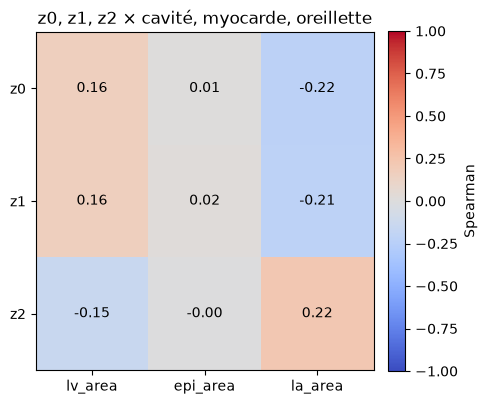

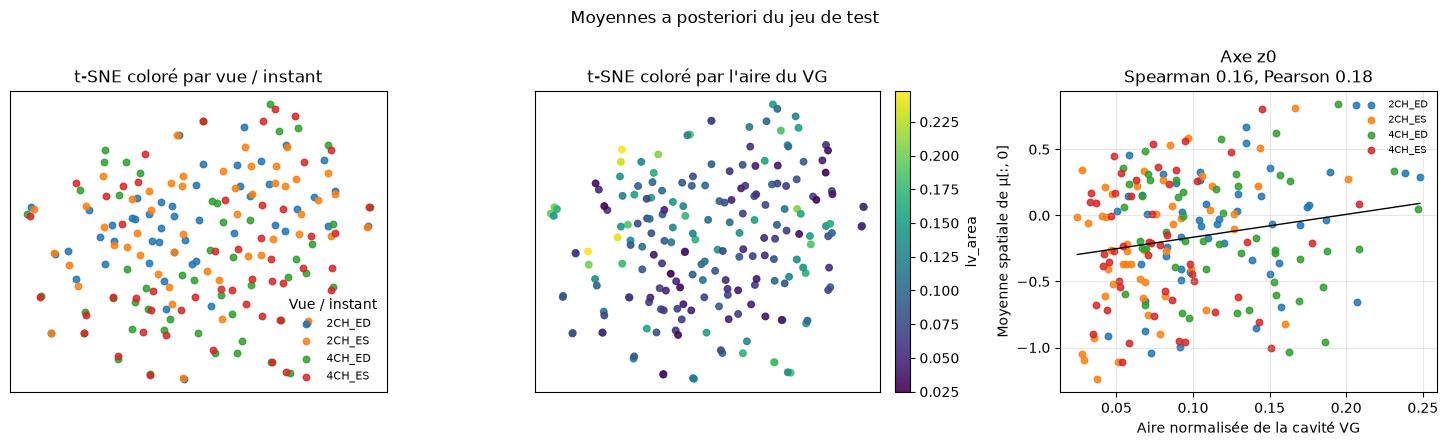

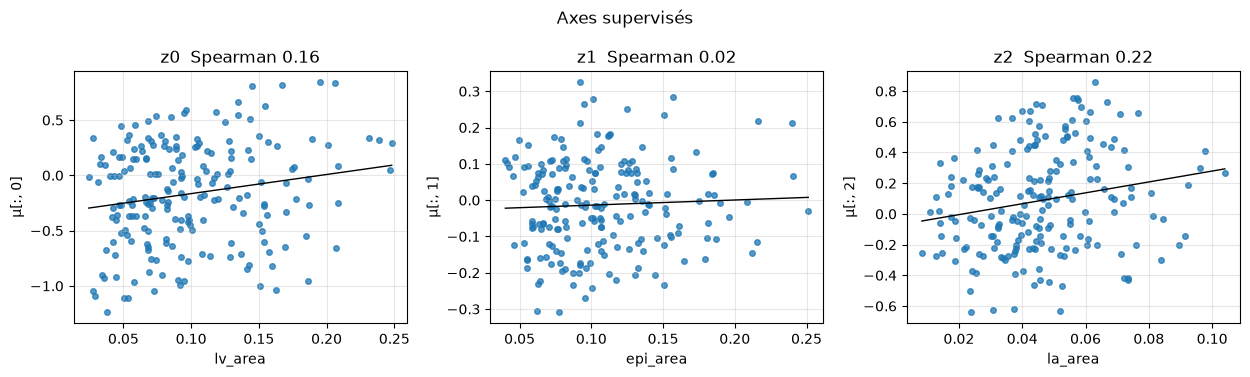

In [15]:
mu_np = test_pred["mu"].numpy()
flat = mu_np.reshape(mu_np.shape[0], -1)
print(f"Matrice passée à t-SNE : {flat.shape} = (images de test, coefficients latents).")
embedding = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    random_state=SEED,
).fit_transform(flat)
print(f"Projection t-SNE : {embedding.shape}")

z_means = [
    test_pred["mu"][:, channel].mean(dim=(1, 2)).numpy()
    for channel in range(3)
]
z0 = z_means[0]
lv_area = np.asarray(test_pred["lv_area"], dtype=np.float64)
epi_area = np.asarray(test_pred["epi_area"], dtype=np.float64)
la_area = np.asarray(test_pred["la_area"], dtype=np.float64)
area_bank = (lv_area, epi_area, la_area)
area_names = ("lv_area", "epi_area", "la_area")
axis_names = ("z0", "z1", "z2")

spearman_matrix = np.zeros((3, 3), dtype=np.float64)
pvalue_matrix = np.zeros((3, 3), dtype=np.float64)
for row, latent_values in enumerate(z_means):
    for column, attribute_values in enumerate(area_bank):
        rho, p_value = spearmanr(latent_values, attribute_values)
        spearman_matrix[row, column] = float(rho)
        pvalue_matrix[row, column] = float(p_value)
        print(
            f"Spearman({axis_names[row]}, {area_names[column]}) = {rho:.3f}  "
            f"(p = {p_value:.3g})"
        )

spearman_rho = float(spearman_matrix[0, 0])
spearman_p = float(pvalue_matrix[0, 0])
pearson_r, pearson_p = pearsonr(z0, lv_area)
print(f"Pearson(z0, lv_area)  = {pearson_r:.3f}  (p = {pearson_p:.3g})")

within_view = {}
for view in ("2CH", "4CH"):
    selected = test_pred["view"] == view
    rho, p_value = spearmanr(z0[selected], lv_area[selected])
    within_view[view] = {
        "spearman": float(rho),
        "pvalue": float(p_value),
        "n": int(selected.sum()),
    }
    print(f"Spearman(z0, lv_area) dans la vue {view} (n = {int(selected.sum())}) : {rho:.3f}  (p = {p_value:.3g})")

column_exp6["spearman"] = spearman_rho
column_exp6["spearman_z1"] = float(spearman_matrix[1, 1])
column_exp6["spearman_z2"] = float(spearman_matrix[2, 2])
attribute_stats = {
    name: {
        "axis": axis_names[index],
        "spearman": float(spearman_matrix[index, index]),
        "pvalue": float(pvalue_matrix[index, index]),
    }
    for index, name in enumerate(area_names)
}

matrix_rows = []
for row, axis_name in enumerate(axis_names):
    matrix_rows.append([axis_name, *[f"{spearman_matrix[row, column]:.3f}" for column in range(3)]])
display(Markdown(
    "### Matrice de Spearman, axes supervisés\n\n"
    + markdown_table(["Axe", *area_names], matrix_rows)
))


def spearman_line(label, key):
    displays = []
    values = []
    for column in ordered:
        value = column.get(key)
        if value is None:
            displays.append("n.d.")
            values.append(None)
        else:
            displays.append(f"{value:.3f}")
            values.append(float(value))
    return [label, *mark_best(displays, values, higher=True)]


spearman_rows = [
    spearman_line("Spearman(z0, lv_area)", "spearman"),
    spearman_line("Spearman(z1, epi_area)", "spearman_z1"),
    spearman_line("Spearman(z2, la_area)", "spearman_z2"),
]
display(Markdown(
    "### Spearman des axes supervisés\n\n"
    + markdown_table(headers, table_rows + spearman_rows)
))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
heat = ax.imshow(spearman_matrix, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(3), list(area_names))
ax.set_yticks(range(3), list(axis_names))
for row in range(3):
    for column in range(3):
        ax.text(column, row, f"{spearman_matrix[row, column]:.2f}", ha="center", va="center")
fig.colorbar(heat, ax=ax, fraction=0.046, pad=0.04, label="Spearman")
ax.set_title("z0, z1, z2 × cavité, myocarde, oreillette")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.5))
for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    axes[0].scatter(
        embedding[selected, 0],
        embedding[selected, 1],
        s=22,
        alpha=0.85,
        label=view_instant,
    )
axes[0].legend(frameon=False, title="Vue / instant", fontsize=8)
axes[0].set_title("t-SNE coloré par vue / instant")
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].grid(True, color="0.9")

area_scatter = axes[1].scatter(
    embedding[:, 0],
    embedding[:, 1],
    c=lv_area,
    cmap="viridis",
    s=22,
    alpha=0.9,
)
axes[1].set_title("t-SNE coloré par l'aire du VG")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].grid(True, color="0.9")
fig.colorbar(area_scatter, ax=axes[1], fraction=0.046, pad=0.04, label="lv_area")

for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    axes[2].scatter(lv_area[selected], z0[selected], s=22, alpha=0.85, label=view_instant)
order = np.argsort(lv_area)
slope, intercept = np.polyfit(lv_area, z0, 1)
axes[2].plot(lv_area[order], slope * lv_area[order] + intercept, color="black", lw=1.0)
axes[2].set_xlabel("Aire normalisée de la cavité VG")
axes[2].set_ylabel("Moyenne spatiale de μ[:, 0]")
axes[2].set_title(f"Axe z0\nSpearman {spearman_rho:.2f}, Pearson {pearson_r:.2f}")
axes[2].grid(True, alpha=0.3)
axes[2].legend(frameon=False, fontsize=7)
fig.suptitle("Moyennes a posteriori du jeu de test")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.8))
for axis, (latent_values, attribute_values, attribute_name) in enumerate(zip(z_means, area_bank, area_names)):
    axes[axis].scatter(attribute_values, latent_values, s=16, alpha=0.75, color="tab:blue")
    order = np.argsort(attribute_values)
    slope, intercept = np.polyfit(attribute_values, latent_values, 1)
    axes[axis].plot(
        attribute_values[order],
        slope * attribute_values[order] + intercept,
        color="black",
        lw=1.0,
    )
    axes[axis].set_xlabel(attribute_name)
    axes[axis].set_ylabel(f"μ[:, {axis}]")
    axes[axis].set_title(f"{axis_names[axis]}  Spearman {spearman_matrix[axis, axis]:.2f}")
    axes[axis].grid(True, alpha=0.3)
fig.suptitle("Axes supervisés")
fig.tight_layout()
plt.show()


### Interpolation ED → ES

Le trajet relie la moyenne a posteriori de la télédiastole à celle de la télésystole pour `patient0010` en vue 4CH, les deux cadres étant dans le test. Le GIF fait l'aller puis le retour.


patient0010 4CH : interpolation de μ_ED vers μ_ES, 16 pas.
GIF aller-retour enregistré dans artifacts\exp6_interp_ED_ES.gif.


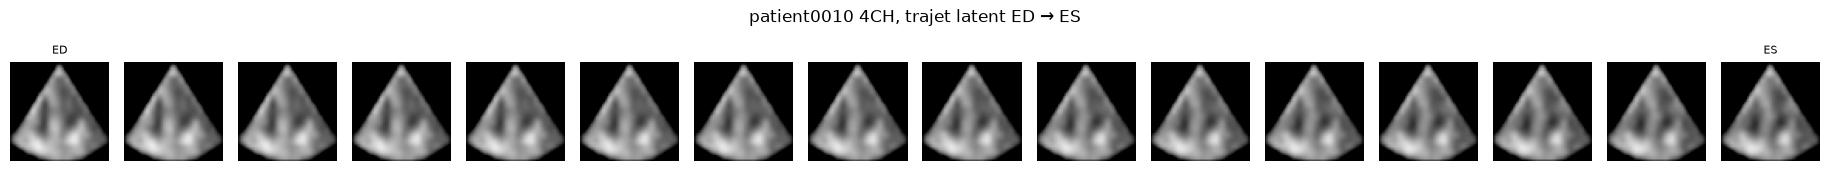

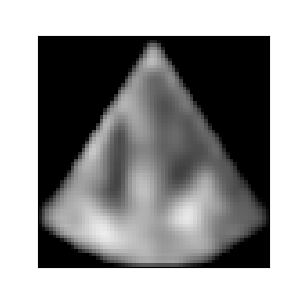

In [16]:
def pair_index(dataset):
    pairs = {}
    for index, record in enumerate(dataset.records):
        pairs.setdefault((record["patient"], record["view"]), {})[record["instant"]] = index
    return pairs


def encode_mu(model, dataset, index):
    image = dataset[index]["image"][None].to(device, non_blocking=True)
    with torch.no_grad():
        mu, _ = model.encode(image)
    return mu


def interpolate(model, z_start, z_end, steps):
    weights = torch.linspace(0, 1, steps, device=z_start.device)
    codes = torch.cat([torch.lerp(z_start, z_end, float(weight)) for weight in weights], dim=0)
    with torch.no_grad():
        frames = decode_image(model, codes)[:, 0].cpu().numpy()
    return frames


def save_gif(frames, path, fps=8):
    fig, ax = plt.subplots(figsize=(3, 3))
    shown = ax.imshow(frames[0], cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])

    def update(frame_index):
        shown.set_data(frames[frame_index])
        return [shown]

    animation = FuncAnimation(fig, update, frames=len(frames), interval=1000 / fps, blit=True)
    animation.save(path, writer="pillow", fps=fps)
    plt.close(fig)
    return animation


pairs = pair_index(test_dataset)
gif_key = ("patient0010", "4CH")
if gif_key not in pairs or not {"ED", "ES"} <= set(pairs[gif_key]):
    raise RuntimeError(f"Paire ED/ES introuvable pour {gif_key} dans le test.")
ed_index = pairs[gif_key]["ED"]
es_index = pairs[gif_key]["ES"]
gif_patient, gif_view = gif_key

z_ed = encode_mu(model, test_dataset, ed_index)
z_es = encode_mu(model, test_dataset, es_index)
forward = interpolate(model, z_ed, z_es, steps=16)
cycle = np.concatenate([forward, forward[-2:0:-1]], axis=0)

gif_path = ARTIFACT_DIR / "exp6_interp_ED_ES.gif"
save_gif(cycle, gif_path, fps=8)
print(f"{gif_patient} {gif_view} : interpolation de μ_ED vers μ_ES, {forward.shape[0]} pas.")
print(f"GIF aller-retour enregistré dans {gif_path}.")

fig, axes = plt.subplots(1, forward.shape[0], figsize=(1.15 * forward.shape[0], 1.8))
for ax, frame in zip(axes, forward):
    ax.imshow(frame, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
axes[0].set_title("ED", fontsize=8)
axes[-1].set_title("ES", fontsize=8)
fig.suptitle(f"{gif_patient} {gif_view}, trajet latent ED → ES")
fig.tight_layout()
plt.show()

display(Image(filename=str(gif_path)))


### Balayage des trois axes latents supervisés

Chaque GIF part d'un cadre de test dont l'attribut correspondant est médian. Seule la moyenne spatiale du canal supervisé est déplacée, du 5e au 95e percentile de cet axe sur le test, puis le trajet revient. Les autres coefficients restent ceux de l'image d'origine. `z0` suit la cavité, `z1` le myocarde, `z2` l'oreillette.


Balayage de z0 sur patient0272 4CH_ES : -0.959 → 0.540, 16 pas.
GIF de balayage enregistré dans artifacts\exp6_latent_sweep_z0.gif.


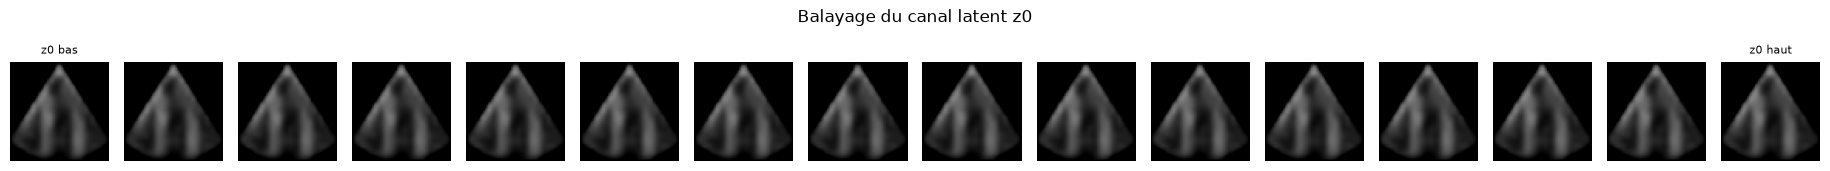

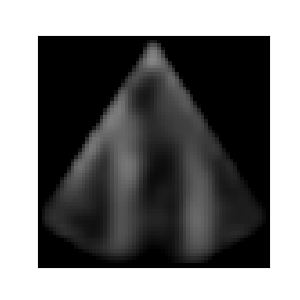

Balayage de z1 sur patient0124 2CH_ES : -0.207 → 0.181, 16 pas.
GIF de balayage enregistré dans artifacts\exp6_latent_sweep_z1.gif.


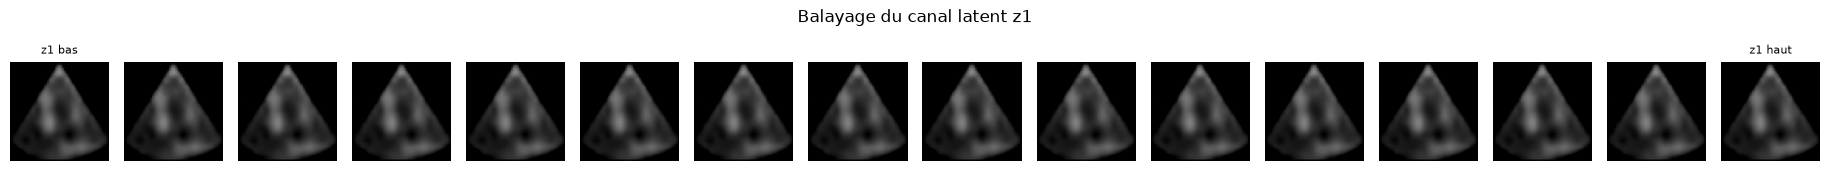

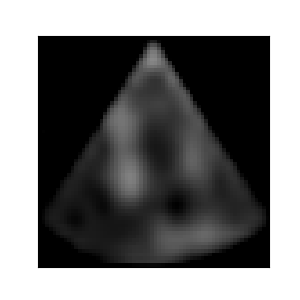

Balayage de z2 sur patient0299 4CH_ED : -0.421 → 0.663, 16 pas.
GIF de balayage enregistré dans artifacts\exp6_latent_sweep_z2.gif.


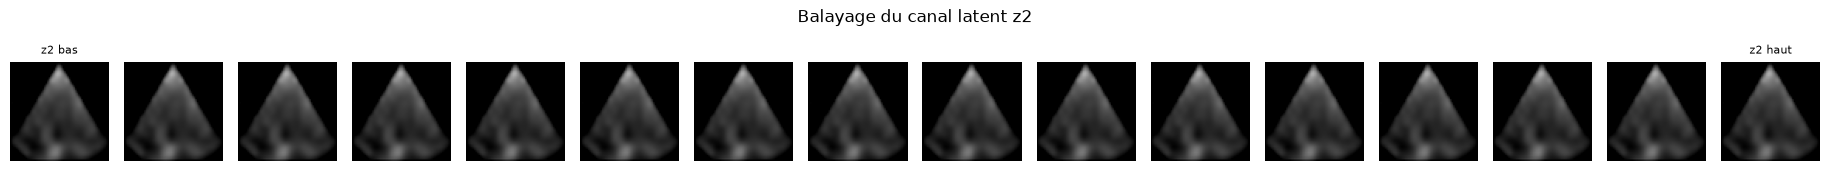

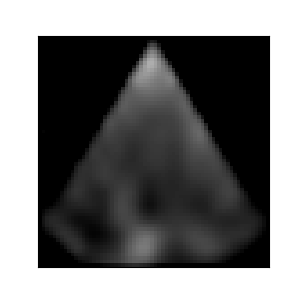

In [17]:
def latent_sweep(channel, attribute_values, gif_name, low_title, high_title):
    median_order = np.argsort(attribute_values)
    sweep_index = int(median_order[len(median_order) // 2])
    base_mu = test_pred["mu"][sweep_index:sweep_index + 1].to(device)
    channel_values = test_pred["mu"][:, channel].mean(dim=(1, 2))
    base_value = base_mu[:, channel].mean()
    low = torch.quantile(channel_values.to(device), 0.05)
    high = torch.quantile(channel_values.to(device), 0.95)
    targets = torch.linspace(float(low), float(high), 16, device=device)
    frames = []
    with torch.no_grad():
        for target in targets:
            shifted = base_mu.clone()
            shifted[:, channel] = shifted[:, channel] + (target - base_value)
            frames.append(decode_image(model, shifted)[0, 0].cpu().numpy())
    forward = np.stack(frames, axis=0)
    cycle = np.concatenate([forward, forward[-2:0:-1]], axis=0)
    path = ARTIFACT_DIR / gif_name
    save_gif(cycle, path, fps=8)
    print(
        f"Balayage de z{channel} sur {test_pred['patient'][sweep_index]} "
        f"{test_pred['view_instant'][sweep_index]} : "
        f"{float(low):.3f} → {float(high):.3f}, {forward.shape[0]} pas."
    )
    print(f"GIF de balayage enregistré dans {path}.")
    fig, axes = plt.subplots(1, forward.shape[0], figsize=(1.15 * forward.shape[0], 1.8))
    for ax, frame in zip(axes, forward):
        ax.imshow(frame, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    axes[0].set_title(low_title, fontsize=8)
    axes[-1].set_title(high_title, fontsize=8)
    fig.suptitle(f"Balayage du canal latent z{channel}")
    fig.tight_layout()
    plt.show()
    display(Image(filename=str(path)))
    return path


sweep_gif_paths = [
    latent_sweep(0, test_pred["lv_area"], "exp6_latent_sweep_z0.gif", "z0 bas", "z0 haut"),
    latent_sweep(1, test_pred["epi_area"], "exp6_latent_sweep_z1.gif", "z1 bas", "z1 haut"),
    latent_sweep(2, test_pred["la_area"], "exp6_latent_sweep_z2.gif", "z2 bas", "z2 haut"),
]
sweep_gif_path = sweep_gif_paths[0]


In [18]:
results_exp6 = {
    "experiment": 6,
    "seed": SEED,
    "device": str(device),
    "gpu": gpu_name,
    "vram_bytes": int(vram_total),
    "torch": torch.__version__,
    "monai": monai.__version__,
    "beta_max": BETA_MAX,
    "warmup_epochs": WARMUP_EPOCHS,
    "gamma": GAMMA,
    "delta": DELTA,
    "recon_loss": CONFIG["recon_loss"],
    "heart_weight_map": "1 + 4.0 * (label > 0)",
    "attribute": (
        "spatial means of mu[:, 0], mu[:, 1], mu[:, 2] ranked with "
        "lv cavity (label == 1), myocardium (label == 2) and left atrium (label == 3); "
        "channels 3:16 unconstrained"
    ),
    "ema_decay": EMA_DECAY,
    "channels": list(CHANNELS),
    "attention_levels": list(ATTENTION_LEVELS),
    "num_res_blocks": NUM_RES_BLOCKS,
    "latent_shape": list(LATENT_SHAPE),
    "n_params": N_PARAMS,
    "optimizer": "AdamW",
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "eta_min": ETA_MIN,
    "precision": "fp32",
    "epochs": history["epochs"],
    "best_epoch": history["best_epoch"],
    "best_val_recon": history["best_val"],
    "seconds": history["seconds"],
    "seconds_per_epoch": history["seconds"] / history["epochs"],
    "max_memory_mb": history.get("max_memory_mb"),
    "history": {
        key: value
        for key, value in history.items()
        if key != "config"
    },
    "test": {
        "n": len(test_dataset),
        "mse_mean": exp6_mse,
        "mse_std": exp6_mse_std,
        "mae_mean": exp6_mae,
        "mae_std": exp6_mae_std,
        "psnr_mean": exp6_psnr,
        "psnr_std": exp6_psnr_std,
        "ssim_mean": exp6_ssim,
        "ssim_std": exp6_ssim_std,
        "heart_mse_mean": exp6_heart,
        "heart_mse_std": exp6_heart_std,
        "heart_psnr_mean": exp6_heart_psnr,
        "heart_psnr_std": exp6_heart_psnr_std,
        "background_mse_mean": exp6_background,
        "background_mse_std": exp6_background_std,
        "per_view_instant": per_view_instant,
    },
    "latent_attribute": {
        "spearman_mu0_lv_area": float(spearman_rho),
        "spearman_pvalue": float(spearman_p),
        "spearman_mu1_epi_area": float(spearman_matrix[1, 1]),
        "spearman_mu1_pvalue": float(pvalue_matrix[1, 1]),
        "spearman_mu2_la_area": float(spearman_matrix[2, 2]),
        "spearman_mu2_pvalue": float(pvalue_matrix[2, 2]),
        "pearson_mu0_lv_area": float(pearson_r),
        "pearson_pvalue": float(pearson_p),
        "spearman_matrix": spearman_matrix.tolist(),
        "pvalue_matrix": pvalue_matrix.tolist(),
        "by_attribute": attribute_stats,
        "within_view": within_view,
        "n": int(len(z0)),
    },
    "interpolation_gif": str(gif_path),
    "latent_sweep_gif": str(sweep_gif_path),
    "latent_sweep_gifs": [str(path) for path in sweep_gif_paths],
    "comparison": comparison_columns,
}

exp5_reference = {
    "mse": column_exp5["mse"],
    "heart_mse": column_exp5["heart_mse"],
    "ssim": column_exp5["ssim"],
    "psnr": column_exp5["psnr"],
}
fidelity_checks = {
    "MSE < expérience 5": exp6_mse < exp5_reference["mse"],
    "MSE cœur < expérience 5": exp6_heart < exp5_reference["heart_mse"],
    "SSIM > expérience 5": exp6_ssim > exp5_reference["ssim"],
    "PSNR > expérience 5": exp6_psnr > exp5_reference["psnr"],
    "Spearman(z0, lv_area) > 0.85": float(spearman_rho) > 0.85,
}
aim_checks = {
    "MSE test < 0.0018": exp6_mse < 0.0018,
    "MSE cœur < 0.0030": exp6_heart < 0.0030,
    "SSIM > 0.85": exp6_ssim > 0.85,
    "PSNR > 27.5 dB": exp6_psnr > 27.5,
    "Spearman(z1, myocarde) > 0.85": float(spearman_matrix[1, 1]) > 0.85,
    "Spearman(z2, la_area) > 0.85": float(spearman_matrix[2, 2]) > 0.85,
}
results_exp6["fidelity_checks"] = fidelity_checks
results_exp6["aim_checks"] = aim_checks
results_exp6["experiment_5_reference"] = exp5_reference

results_path = ARTIFACT_DIR / "results_exp6.json"
results_path.write_text(
    json.dumps(results_exp6, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)


def checklist(title, checks):
    lines = [f"### {title}", ""]
    for label, passed in checks.items():
        mark = "oui" if passed else "non"
        lines.append(f"- {label} : {mark}")
    return "\n".join(lines)


def signed(value, digits):
    return f"{value:+.{digits}f}"


latent_text = "×".join(str(value) for value in LATENT_SHAPE)
synthesis = "\n".join([
    "## Synthèse",
    "",
    (
        f"L'expérience 6 entraîne {fmt_int(N_PARAMS)} paramètres, canaux {tuple(CHANNELS)}, "
        f"attention aux deux dernières échelles, code latent {latent_text}, pendant {history['epochs']} époques "
        f"sur {gpu_name}. Le checkpoint retenu est l'époque {history['best_epoch']}, "
        f"la plus faible reconstruction EMA de validation après le warmup "
        f"({history['best_val']:.5f}). La boucle dure {history['seconds'] / 60:.2f} min, "
        f"soit {history['seconds'] / history['epochs']:.2f} s par époque. "
        f"Le pic de VRAM mesuré pendant cette boucle est {history.get('max_memory_mb', float('nan')):.0f} Mo."
    ),
    "",
    (
        f"Sur les 200 images de test, la MSE vaut {exp6_mse:.5f}, le PSNR {exp6_psnr:.2f} dB, "
        f"le SSIM {exp6_ssim:.3f} et la MAE {exp6_mae:.3f}. "
        f"Par rapport à l'expérience 5 (MSE {exp5_reference['mse']:.5f}, "
        f"PSNR {exp5_reference['psnr']:.2f} dB, SSIM {exp5_reference['ssim']:.3f}), "
        f"l'écart de MSE est {signed(exp6_mse - exp5_reference['mse'], 5)}, "
        f"l'écart de PSNR est {signed(exp6_psnr - exp5_reference['psnr'], 2)} dB "
        f"et l'écart de SSIM est {signed(exp6_ssim - exp5_reference['ssim'], 3)}."
    ),
    "",
    (
        f"La MSE sur le cœur vaut {exp6_heart:.5f} "
        f"(expérience 5 : {exp5_reference['heart_mse']:.5f}, écart "
        f"{signed(exp6_heart - exp5_reference['heart_mse'], 5)}). "
        f"Le PSNR dans le masque cardiaque vaut {exp6_heart_psnr:.2f} dB. "
        f"La MSE de fond vaut {exp6_background:.5f}. "
        f"Le poids W = 1 + {HEART_WEIGHT:.1f} sur les pixels de cœur. "
        "La perte ajoute le SSIM à 32×32, la L1 des gradients et la L1 des amplitudes FFT."
    ),
    "",
    (
        f"Spearman(z0, aire du VG) = {spearman_rho:.3f} (p = {spearman_p:.3g}), Pearson = {pearson_r:.3f}. "
        f"Spearman(z1, myocarde) = {attribute_stats['epi_area']['spearman']:.3f}, "
        f"Spearman(z2, aire de l'oreillette) = {attribute_stats['la_area']['spearman']:.3f}. "
        f"Les trois axes sont dans la perte, avec γ = {GAMMA:.3f} partagé et β max = {BETA_MAX:.0e}. "
        f"Les canaux 3 à 15 restent libres. "
        f"À l'intérieur de chaque vue, Spearman(z0) 2CH = {within_view['2CH']['spearman']:.3f} et "
        f"Spearman(z0) 4CH = {within_view['4CH']['spearman']:.3f}."
    ),
    "",
    (
        "Le calcul est resté en FP32, sans TF32. La validation et le test décodent μ. "
        "Les poids sauvegardés sont la moyenne mobile exponentielle, decay "
        f"{EMA_DECAY}, mise à jour à chaque lot à partir de l'époque {WARMUP_EPOCHS}. "
        "Les tenseurs d'entraînement et de validation étaient en VRAM avant la première époque, "
        "et les moyennes de perte n'ont été lues sur le CPU qu'une fois par époque. "
        "Le fichier de poids n'a été écrit qu'à la fin."
    ),
    "",
    checklist("Dépassement de l'expérience 5", fidelity_checks),
    "",
    checklist("Cibles visées", aim_checks),
])
display(Markdown(synthesis))
print(f"Résultats écrits dans {results_path}.")
print(
    f"Expérience 6 — meilleure époque {history['best_epoch']}/{history['epochs']}, "
    f"MSE test {exp6_mse:.5f}, PSNR {exp6_psnr:.2f} dB, "
    f"SSIM {exp6_ssim:.3f}, MSE cœur {exp6_heart:.5f}, "
    f"PSNR cœur {exp6_heart_psnr:.2f} dB, "
    f"Spearman z0 {spearman_rho:.3f}, z1 {spearman_matrix[1, 1]:.3f}, z2 {spearman_matrix[2, 2]:.3f}, "
    f"durée {history['seconds'] / 60:.2f} min."
)


## Synthèse

L'expérience 6 entraîne 49 122 305 paramètres, canaux (64, 128, 256, 512), attention aux deux dernières échelles, code latent 16×8×8, pendant 150 époques sur NVIDIA GeForce RTX 4060 Ti. Le checkpoint retenu est l'époque 150, la plus faible reconstruction EMA de validation après le warmup (0.08654). La boucle dure 39.27 min, soit 15.71 s par époque. Le pic de VRAM mesuré pendant cette boucle est 5781 Mo.

Sur les 200 images de test, la MSE vaut 0.00609, le PSNR 22.49 dB, le SSIM 0.682 et la MAE 0.042. Par rapport à l'expérience 5 (MSE 0.00268, PSNR 26.04 dB, SSIM 0.808), l'écart de MSE est +0.00341, l'écart de PSNR est -3.55 dB et l'écart de SSIM est -0.126.

La MSE sur le cœur vaut 0.00842 (expérience 5 : 0.00446, écart +0.00397). Le PSNR dans le masque cardiaque vaut 21.00 dB. La MSE de fond vaut 0.00539. Le poids W = 1 + 4.0 sur les pixels de cœur. La perte ajoute le SSIM à 32×32, la L1 des gradients et la L1 des amplitudes FFT.

Spearman(z0, aire du VG) = 0.156 (p = 0.0269), Pearson = 0.185. Spearman(z1, myocarde) = 0.018, Spearman(z2, aire de l'oreillette) = 0.220. Les trois axes sont dans la perte, avec γ = 0.025 partagé et β max = 1e-05. Les canaux 3 à 15 restent libres. À l'intérieur de chaque vue, Spearman(z0) 2CH = 0.326 et Spearman(z0) 4CH = -0.017.

Le calcul est resté en FP32, sans TF32. La validation et le test décodent μ. Les poids sauvegardés sont la moyenne mobile exponentielle, decay 0.995, mise à jour à chaque lot à partir de l'époque 20. Les tenseurs d'entraînement et de validation étaient en VRAM avant la première époque, et les moyennes de perte n'ont été lues sur le CPU qu'une fois par époque. Le fichier de poids n'a été écrit qu'à la fin.

### Dépassement de l'expérience 5

- MSE < expérience 5 : non
- MSE cœur < expérience 5 : non
- SSIM > expérience 5 : non
- PSNR > expérience 5 : non
- Spearman(z0, lv_area) > 0.85 : non

### Cibles visées

- MSE test < 0.0018 : non
- MSE cœur < 0.0030 : non
- SSIM > 0.85 : non
- PSNR > 27.5 dB : non
- Spearman(z1, myocarde) > 0.85 : non
- Spearman(z2, la_area) > 0.85 : non

Résultats écrits dans artifacts\results_exp6.json.
Expérience 6 — meilleure époque 150/150, MSE test 0.00609, PSNR 22.49 dB, SSIM 0.682, MSE cœur 0.00842, PSNR cœur 21.00 dB, Spearman z0 0.156, z1 0.018, z2 0.220, durée 39.27 min.
